In [1]:

# STEP 1: Install Java 17

!apt-get update -qq
!apt-get install -y openjdk-17-jdk-headless -qq

# Configure Java environment
import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

# Verify Java installation
!java -version


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.20.1+1-1~24.04_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.20.1+1-1~24.04) ...
Selecting previously unselected package openjdk-17-jdk-headless:amd64.
Preparing to unpack .../openjdk-17-jdk-headless_17.0.20.1+1-1~24.04_amd64.deb ...
Unpacking openjdk-17-jdk-headless:amd64 (17.0.20.1+1-1~24.04) ...
Setting up openjdk-17-jre-headless:amd64 (17.0.20.1+1-1~24.04) ...
Processing triggers for ca-certificates-java (20240118) ...
[0.022s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.022s

In [2]:

# STEP 2: Install PySpark

!pip install -q pyspark==3.5.6

# Verify PySpark installation
import pyspark

print("PySpark version:", pyspark.__version__)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.6 which is incompatible.
PySpark version: 3.5.6


In [3]:

# STEP 3: Initialize Spark

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("YottaFlex_Skew_Aware_Pipeline")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.adaptive.enabled", "false")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)

print("Spark session created successfully!")
print("Spark version:", spark.version)
print("Application:", spark.sparkContext.appName)
print("Master:", spark.sparkContext.master)
print("Default parallelism:", spark.sparkContext.defaultParallelism)


Spark session created successfully!
Spark version: 3.5.6
Application: YottaFlex_Skew_Aware_Pipeline
Master: local[*]
Default parallelism: 2


In [4]:

# STEP 4: First Spark DataFrame

data = [
    (1, "UPI", 500),
    (2, "Credit Card", 1200),
    (3, "Debit Card", 800),
    (4, "UPI", 250),
    (5, "Cash", 400)
]

columns = ["transaction_id", "payment_method", "amount"]

df = spark.createDataFrame(data, columns)

# Display records
df.show()

# Display schema
df.printSchema()

# Count records
print("Total records:", df.count())


+--------------+--------------+------+
|transaction_id|payment_method|amount|
+--------------+--------------+------+
|             1|           UPI|   500|
|             2|   Credit Card|  1200|
|             3|    Debit Card|   800|
|             4|           UPI|   250|
|             5|          Cash|   400|
+--------------+--------------+------+

root
 |-- transaction_id: long (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- amount: long (nullable = true)

Total records: 5


In [5]:

# PHASE 2 - STEP 1
# Create project directory structure

import os

PROJECT_ROOT = "/content/yottaflex_project"

directories = [
    "data/raw",
    "data/processed",
    "data/rejected",
    "data/sample",
    "src",
    "tests",
    "reports",
    "docs",
    "logs"
]

for directory in directories:
    path = os.path.join(PROJECT_ROOT, directory)
    os.makedirs(path, exist_ok=True)

print("Project structure created successfully!")

for root, dirs, files in os.walk(PROJECT_ROOT):
    level = root.replace(PROJECT_ROOT, "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")


Project structure created successfully!
yottaflex_project/
    tests/
    reports/
    logs/
    data/
        rejected/
        raw/
        processed/
        sample/
    src/
    docs/


In [6]:

%%writefile /content/yottaflex_project/src/config.py

from pathlib import Path

# Project configuration
PROJECT_ROOT = Path("/content/yottaflex_project")

# Data directories
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REJECTED_DIR = PROJECT_ROOT / "data" / "rejected"
SAMPLE_DIR = PROJECT_ROOT / "data" / "sample"

REPORT_DIR = PROJECT_ROOT / "reports"
LOG_DIR = PROJECT_ROOT / "logs"
DOCS_DIR = PROJECT_ROOT / "docs"

# Reproducibility
RANDOM_SEED = 42

# Dataset configuration
NUM_TRANSACTIONS = 100_000
NUM_MERCHANTS = 1_000
NUM_CUSTOMERS = 20_000

# Data skew configuration
NUM_HOT_MERCHANTS = 5
HOT_MERCHANT_SHARE = 0.60

# Spark configuration
SHUFFLE_PARTITIONS = 8

# Output filenames
TRANSACTION_FILE = RAW_DIR / "transactions.csv"
MERCHANT_FILE = RAW_DIR / "merchants.csv"

print("Configuration loaded successfully.")


Writing /content/yottaflex_project/src/config.py


In [7]:

# PHASE 2 - STEP 5
# Generate reproducible synthetic transaction data

import numpy as np
import pandas as pd
from pathlib import Path

from sys import path
path.append("/content/yottaflex_project/src")

from config import *

# Initialize random generator
rng = np.random.default_rng(RANDOM_SEED)

# 1. Generate merchant reference data
merchant_ids = [
    f"MER_{i:04d}"
    for i in range(1, NUM_MERCHANTS + 1)
]

merchant_data = pd.DataFrame({
    "merchant_id": merchant_ids,
    "merchant_name": [
        f"Merchant_{i:04d}"
        for i in range(1, NUM_MERCHANTS + 1)
    ],
    "merchant_tier": [
        "PREMIUM" if i <= 5 else "STANDARD"
        for i in range(1, NUM_MERCHANTS + 1)
    ]
})

# 2. Define merchant probability distribution
hot_probability = (
    HOT_MERCHANT_SHARE / NUM_HOT_MERCHANTS
)

normal_probability = (
    (1 - HOT_MERCHANT_SHARE) /
    (NUM_MERCHANTS - NUM_HOT_MERCHANTS)
)

merchant_probabilities = np.array(
    [hot_probability] * NUM_HOT_MERCHANTS +
    [normal_probability] *
    (NUM_MERCHANTS - NUM_HOT_MERCHANTS)
)

# 3. Generate transaction records
selected_merchants = rng.choice(
    merchant_ids,
    size=NUM_TRANSACTIONS,
    p=merchant_probabilities
)

customer_numbers = rng.integers(
    1, NUM_CUSTOMERS + 1, size=NUM_TRANSACTIONS
)

amounts = np.round(
    rng.uniform(50, 50000, size=NUM_TRANSACTIONS), 2
)

payment_methods = rng.choice(
    ["UPI", "CREDIT_CARD", "DEBIT_CARD", "CASH"],
    size=NUM_TRANSACTIONS,
    p=[0.55, 0.20, 0.15, 0.10]
)

statuses = rng.choice(
    ["SUCCESS", "FAILED"],
    size=NUM_TRANSACTIONS,
    p=[0.96, 0.04]
)

# Random timestamps between January and September 2026
start_time = pd.Timestamp("2026-01-01", tz="UTC")
end_time = pd.Timestamp("2026-10-01", tz="UTC")

start_seconds = int(start_time.timestamp())
end_seconds = int(end_time.timestamp())

timestamps = pd.to_datetime(
    rng.integers(
        start_seconds,
        end_seconds,
        size=NUM_TRANSACTIONS
    ),
    unit="s",
    utc=True
)

transactions = pd.DataFrame({
    "transaction_id": [
        f"TXN_{i:09d}"
        for i in range(1, NUM_TRANSACTIONS + 1)
    ],
    "merchant_id": selected_merchants,
    "customer_id": [
        f"CUS_{i:06d}" for i in customer_numbers
    ],
    "transaction_amount": amounts,
    "payment_method": payment_methods,
    "transaction_status": statuses,
    "transaction_timestamp": timestamps
})

# 4. Save raw source datasets
merchant_data.to_csv(
    MERCHANT_FILE, index=False
)

transactions.to_csv(
    TRANSACTION_FILE,
    index=False,
    date_format="%Y-%m-%dT%H:%M:%SZ"
)

print("Dataset generation completed!")
print("Transactions:", len(transactions))
print("Merchants:", len(merchant_data))
print("Random seed:", RANDOM_SEED)
print("Transaction file:", TRANSACTION_FILE)
print("Merchant file:", MERCHANT_FILE)


Configuration loaded successfully.
Dataset generation completed!
Transactions: 100000
Merchants: 1000
Random seed: 42
Transaction file: /content/yottaflex_project/data/raw/transactions.csv
Merchant file: /content/yottaflex_project/data/raw/merchants.csv


In [8]:

# STEP 6: Create starter sample

sample_data = transactions.sample(
    n=1000,
    random_state=RANDOM_SEED
)

sample_path = SAMPLE_DIR / "transactions_sample.csv"

sample_data.to_csv(
    sample_path,
    index=False,
    date_format="%Y-%m-%dT%H:%M:%SZ"
)

print("Sample dataset saved:", sample_path)
print("Sample records:", len(sample_data))


Sample dataset saved: /content/yottaflex_project/data/sample/transactions_sample.csv
Sample records: 1000


In [9]:

# STEP 7: Read source files using Spark

transactions_spark = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(TRANSACTION_FILE))
)

merchants_spark = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(MERCHANT_FILE))
)

print("Transaction schema:")
transactions_spark.printSchema()

print("Merchant schema:")
merchants_spark.printSchema()

print("Transaction count:", transactions_spark.count())
print("Merchant count:", merchants_spark.count())


Transaction schema:
root
 |-- transaction_id: string (nullable = true)
 |-- merchant_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- transaction_amount: double (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- transaction_status: string (nullable = true)
 |-- transaction_timestamp: timestamp (nullable = true)

Merchant schema:
root
 |-- merchant_id: string (nullable = true)
 |-- merchant_name: string (nullable = true)
 |-- merchant_tier: string (nullable = true)

Transaction count: 100000
Merchant count: 1000


In [10]:

# STEP 8: Merchant transaction distribution

from pyspark.sql import functions as F

merchant_distribution = (
    transactions_spark
    .groupBy("merchant_id")
    .agg(
        F.count("*").alias("transaction_count"),
        F.round(F.sum("transaction_amount"), 2)
         .alias("total_transaction_value")
    )
    .orderBy(F.desc("transaction_count"))
)

# Show top 10 merchants
merchant_distribution.show(10, truncate=False)


+-----------+-----------------+-----------------------+
|merchant_id|transaction_count|total_transaction_value|
+-----------+-----------------+-----------------------+
|MER_0005   |12122            |3.0167497423E8         |
|MER_0003   |11990            |3.0050957925E8         |
|MER_0001   |11961            |2.9999578833E8         |
|MER_0002   |11943            |3.0058443646E8         |
|MER_0004   |11828            |2.9611575289E8         |
|MER_0026   |62               |1465966.76             |
|MER_0842   |61               |1375574.56             |
|MER_0505   |59               |1385135.47             |
|MER_0692   |59               |1443817.92             |
|MER_0196   |58               |1333407.73             |
+-----------+-----------------+-----------------------+
only showing top 10 rows



In [11]:

# STEP 9: Quantify data skew

total_transactions = transactions_spark.count()

top_5 = merchant_distribution.limit(5)

top_5_count = (
    top_5
    .agg(F.sum("transaction_count").alias("total"))
    .first()["total"]
)

top_5_percentage = (
    top_5_count / total_transactions
) * 100

print("Total transactions:", total_transactions)
print("Transactions from top 5 merchants:", top_5_count)
print("Top 5 merchant share:", round(top_5_percentage, 2), "%")


Total transactions: 100000
Transactions from top 5 merchants: 59844
Top 5 merchant share: 59.84 %


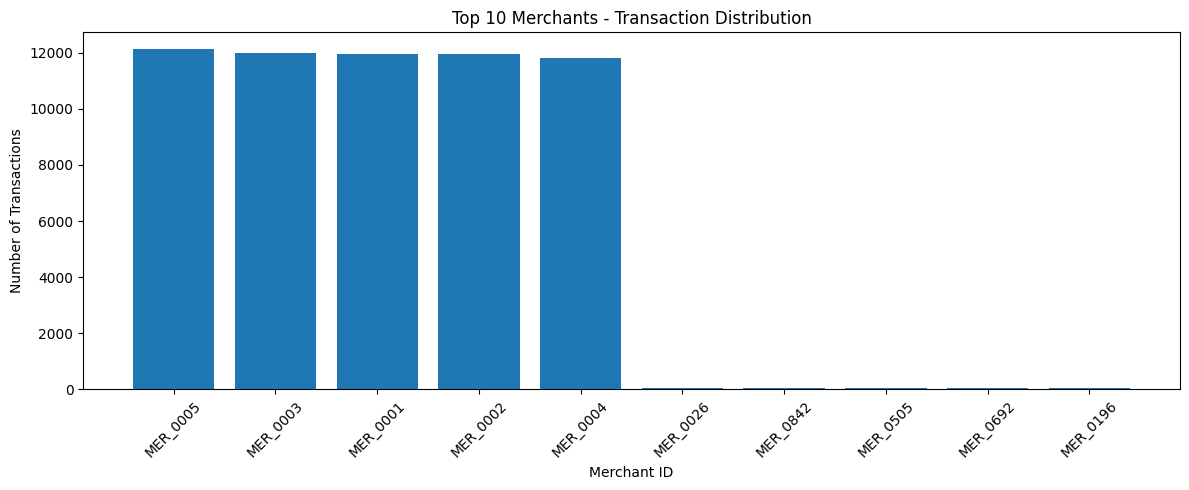

In [12]:

# STEP 10: Visualize skew

import matplotlib.pyplot as plt

top_10_pd = (
    merchant_distribution
    .limit(10)
    .toPandas()
)

plt.figure(figsize=(12, 5))

plt.bar(
    top_10_pd["merchant_id"],
    top_10_pd["transaction_count"]
)

plt.title("Top 10 Merchants - Transaction Distribution")
plt.xlabel("Merchant ID")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [13]:

# STEP 11: Generate deliberately invalid test records

quality_cases = []

# Case 1: Duplicate transaction ID
duplicate = transactions.iloc[0].to_dict()
quality_cases.append(duplicate)

# Case 2: Missing merchant ID
missing_merchant = transactions.iloc[1].to_dict()
missing_merchant["transaction_id"] = "BAD_TXN_001"
missing_merchant["merchant_id"] = None
quality_cases.append(missing_merchant)

# Case 3: Negative transaction amount
negative_amount = transactions.iloc[2].to_dict()
negative_amount["transaction_id"] = "BAD_TXN_002"
negative_amount["transaction_amount"] = -500
quality_cases.append(negative_amount)

# Case 4: Invalid payment method
invalid_method = transactions.iloc[3].to_dict()
invalid_method["transaction_id"] = "BAD_TXN_003"
invalid_method["payment_method"] = "CRYPTO"
quality_cases.append(invalid_method)

# Case 5: Unknown merchant reference
unknown_merchant = transactions.iloc[4].to_dict()
unknown_merchant["transaction_id"] = "BAD_TXN_004"
unknown_merchant["merchant_id"] = "MER_UNKNOWN"
quality_cases.append(unknown_merchant)

# Case 6: Missing transaction amount
missing_amount = transactions.iloc[5].to_dict()
missing_amount["transaction_id"] = "BAD_TXN_005"
missing_amount["transaction_amount"] = None
quality_cases.append(missing_amount)

# Case 7: Invalid transaction status
invalid_status = transactions.iloc[6].to_dict()
invalid_status["transaction_id"] = "BAD_TXN_006"
invalid_status["transaction_status"] = "PENDING_UNKNOWN"
quality_cases.append(invalid_status)

quality_df = pd.DataFrame(quality_cases)

quality_path = SAMPLE_DIR / "quality_test_cases.csv"

quality_df.to_csv(
    quality_path,
    index=False,
    date_format="%Y-%m-%dT%H:%M:%SZ"
)

# Create a separate malformed CSV example
malformed_path = SAMPLE_DIR / "malformed_transactions.csv"

with open(malformed_path, "w") as f:
    f.write(
        "transaction_id,merchant_id,customer_id,"
        "transaction_amount,payment_method,"
        "transaction_status,transaction_timestamp\n"
    )
    f.write("BAD_100,MER_0001,CUS_000001,500,UPI,SUCCESS\n")
    f.write('BAD_101,MER_0002,"BROKEN,500,UPI,SUCCESS,2026-09-01T10:00:00Z\n')
    f.write("BAD_102,MER_0003,CUS_000003,700,UPI,SUCCESS,2026-09-01T11:00:00Z,EXTRA_FIELD\n")

print("Quality test cases:", len(quality_df))
print("Malformed test file:", malformed_path)


Quality test cases: 7
Malformed test file: /content/yottaflex_project/data/sample/malformed_transactions.csv



%%writefile /content/yottaflex_project/docs/data_dictionary.md

# Data Dictionary

## 1. Merchants

| Column | Type | Rule |
|---|---|---|
| merchant_id | STRING | Primary key, required |
| merchant_name | STRING | Required |
| merchant_tier | STRING | PREMIUM / STANDARD |

Grain: One record per merchant.

## 2. Transactions

| Column | Type | Rule |
|---|---|---|
| transaction_id | STRING | Primary key, required |
| merchant_id | STRING | Foreign key, required |
| customer_id | STRING | Required |
| transaction_amount | DECIMAL(12,2) | Positive |
| payment_method | STRING | Allowed payment method |
| transaction_status | STRING | SUCCESS / FAILED |
| transaction_timestamp | TIMESTAMP | UTC event timestamp |

Grain: One record per transaction.

## Relationships

One merchant can have multiple transactions.

merchants.merchant_id references
transactions.merchant_id.

## Business Rules

1. Transaction IDs must be unique.
2. Merchant IDs must exist in the merchant reference.
3. Transaction amounts must be greater than zero.
4. Payment methods must belong to the approved list.
5. Transaction status must be SUCCESS or FAILED.
6. Required fields cannot be null.

## Reproducibility

Random seed: 42

Default dataset: 100,000 transactions.

Five hot merchants collectively receive
approximately 60% of transactions.

## Data lineage

The ingestion pipeline will add run_id
and source_file metadata to processed records.


In [14]:

# STEP 12: Dataset quality verification

print("========== DATASET VERIFICATION ==========")

print("Transaction rows:", len(transactions))
print("Unique transaction IDs:",
      transactions["transaction_id"].nunique())

print("Unique merchants:",
      transactions["merchant_id"].nunique())

print("Null values:")
print(transactions.isnull().sum())

print("Negative amounts:",
      (transactions["transaction_amount"] <= 0).sum())

print("Duplicate transaction IDs:",
      transactions["transaction_id"].duplicated().sum())

print("Quality test cases:", len(quality_df))

assert len(transactions) == 100_000
assert transactions["transaction_id"].nunique() == 100_000
assert transactions["merchant_id"].nunique() == 1_000
assert transactions["transaction_amount"].gt(0).all()
assert transactions.isnull().sum().sum() == 0

print("\nAll valid source dataset checks passed!")


========== DATASET VERIFICATION ==========
Transaction rows: 100000
Unique transaction IDs: 100000
Unique merchants: 1000
Null values:
transaction_id           0
merchant_id              0
customer_id              0
transaction_amount       0
payment_method           0
transaction_status       0
transaction_timestamp    0
dtype: int64
Negative amounts: 0
Duplicate transaction IDs: 0
Quality test cases: 7

All valid source dataset checks passed!


In [15]:

# PHASE 3 - STEP 1
# Define explicit source schemas

from pyspark.sql.types import (
    StructType,
    StructField,
    StringType,
    DecimalType,
    TimestampType
)

# Raw CSV schema:
# Read fields as strings first so malformed values
# can be identified rather than silently lost.

raw_transaction_schema = StructType([
    StructField("transaction_id", StringType(), True),
    StructField("merchant_id", StringType(), True),
    StructField("customer_id", StringType(), True),
    StructField("transaction_amount", StringType(), True),
    StructField("payment_method", StringType(), True),
    StructField("transaction_status", StringType(), True),
    StructField("transaction_timestamp", StringType(), True),
    StructField("_corrupt_record", StringType(), True)
])

# Final curated schema
curated_transaction_schema = StructType([
    StructField("transaction_id", StringType(), False),
    StructField("merchant_id", StringType(), False),
    StructField("customer_id", StringType(), False),
    StructField("transaction_amount", DecimalType(12, 2), False),
    StructField("payment_method", StringType(), False),
    StructField("transaction_status", StringType(), False),
    StructField("transaction_timestamp", TimestampType(), False),
    StructField("run_id", StringType(), False),
    StructField("source_file", StringType(), False)
])

# Merchant reference schema
merchant_schema = StructType([
    StructField("merchant_id", StringType(), False),
    StructField("merchant_name", StringType(), False),
    StructField("merchant_tier", StringType(), False)
])

print("Raw schema:")
raw_transaction_schema.simpleString()

print("\nCurated schema:")
curated_transaction_schema.simpleString()

print("\nSchema definitions created successfully.")


Raw schema:

Curated schema:

Schema definitions created successfully.


In [16]:

# STEP 2: Create a validation test batch

import pandas as pd

# Take 1,000 valid records
valid_test_records = transactions.iloc[:1000].copy()

# Add the deliberately invalid records from Phase 2
validation_batch = pd.concat(
    [valid_test_records, quality_df],
    ignore_index=True
)

validation_input_path = (
    SAMPLE_DIR / "validation_input.csv"
)

validation_batch.to_csv(
    validation_input_path,
    index=False,
    date_format="%Y-%m-%dT%H:%M:%SZ"
)

print("Validation batch created.")
print("Total input records:", len(validation_batch))
print("Expected duplicate transaction ID:",
      transactions.iloc[0]["transaction_id"])
print("Validation file:", validation_input_path)


Validation batch created.
Total input records: 1007
Expected duplicate transaction ID: TXN_000000001
Validation file: /content/yottaflex_project/data/sample/validation_input.csv


In [17]:

# STEP 3: Implement ingestion function

import csv
import uuid
from datetime import datetime, timezone
from pyspark.sql import functions as F

EXPECTED_COLUMNS = [
    "transaction_id",
    "merchant_id",
    "customer_id",
    "transaction_amount",
    "payment_method",
    "transaction_status",
    "transaction_timestamp"
]

def ingest_transactions(file_path, run_id=None):

    file_path = str(file_path)

    # 1. Check file existence
    if not os.path.isfile(file_path):
        raise FileNotFoundError(
            f"Source file not found: {file_path}"
        )

    # 2. Validate CSV header
    with open(file_path, "r", newline="") as file:
        reader = csv.reader(file)
        actual_columns = next(reader, [])

    if actual_columns != EXPECTED_COLUMNS:
        raise ValueError(
            f"Unexpected source schema. "
            f"Expected {EXPECTED_COLUMNS}, "
            f"received {actual_columns}"
        )

    # 3. Generate a run ID if not supplied
    if run_id is None:
        run_id = str(uuid.uuid4())

    # 4. Read using explicit raw schema
    raw_df = (
        spark.read
        .format("csv")
        .option("header", True)
        .option("mode", "PERMISSIVE")
        .option("columnNameOfCorruptRecord", "_corrupt_record")
        .option("timestampFormat", "yyyy-MM-dd'T'HH:mm:ssX")
        .schema(raw_transaction_schema)
        .load(file_path)
    )

    # 5. Attach operational metadata
    raw_df = (
        raw_df
        .withColumn("run_id", F.lit(run_id))
        .withColumn("source_file", F.lit(os.path.basename(file_path)))
        .withColumn(
            "ingested_at",
            F.lit(datetime.now(timezone.utc).isoformat())
        )
    )

    print("Ingestion successful!")
    print("Run ID:", run_id)
    print("Source:", os.path.basename(file_path))
    print("Rows read:", raw_df.count())

    return raw_df


In [18]:

# STEP 4: Test ingestion

RUN_ID = "YF_20261030_001"

raw_transactions = ingest_transactions(
    validation_input_path,
    run_id=RUN_ID
)

raw_transactions.show(5, truncate=False)
raw_transactions.printSchema()


Ingestion successful!
Run ID: YF_20261030_001
Source: validation_input.csv
Rows read: 1007
+--------------+-----------+-----------+------------------+--------------+------------------+---------------------+---------------+---------------+--------------------+--------------------------------+
|transaction_id|merchant_id|customer_id|transaction_amount|payment_method|transaction_status|transaction_timestamp|_corrupt_record|run_id         |source_file         |ingested_at                     |
+--------------+-----------+-----------+------------------+--------------+------------------+---------------------+---------------+---------------+--------------------+--------------------------------+
|TXN_000000001 |MER_0438   |CUS_019902 |42177.69          |UPI           |SUCCESS           |2026-03-12T22:10:16Z |NULL           |YF_20261030_001|validation_input.csv|2026-10-30T09:07:10.242968+00:00|
|TXN_000000002 |MER_0004   |CUS_018778 |37717.74          |CASH          |SUCCESS           |2026-04-

In [19]:

# STEP 5: Load merchant reference

merchant_reference = (
    spark.read
    .option("header", True)
    .schema(merchant_schema)
    .csv(str(MERCHANT_FILE))
)

print("Merchant reference count:",
      merchant_reference.count())

merchant_reference.show(5)


Merchant reference count: 1000
+-----------+-------------+-------------+
|merchant_id|merchant_name|merchant_tier|
+-----------+-------------+-------------+
|   MER_0001|Merchant_0001|      PREMIUM|
|   MER_0002|Merchant_0002|      PREMIUM|
|   MER_0003|Merchant_0003|      PREMIUM|
|   MER_0004|Merchant_0004|      PREMIUM|
|   MER_0005|Merchant_0005|      PREMIUM|
+-----------+-------------+-------------+
only showing top 5 rows



In [21]:

# STEP 6: Implement validation

from pyspark.sql.window import Window

VALID_PAYMENT_METHODS = [
    "UPI",
    "CREDIT_CARD",
    "DEBIT_CARD",
    "CASH"
]

VALID_STATUSES = [
    "SUCCESS",
    "FAILED"
]

def validate_transactions(raw_df, merchant_df):

    # Convert raw strings to typed values
    typed_df = (
        raw_df
        .withColumn(
            "transaction_amount",
            F.expr(
                "try_cast(transaction_amount AS DECIMAL(12,2))"
            )
        )
        .withColumn(
            "transaction_timestamp",
            F.to_timestamp(
                "transaction_timestamp",
                "yyyy-MM-dd'T'HH:mm:ssX"
            )
        )
    )

    # Check whether merchant exists
    valid_merchants = merchant_df.select(
        "merchant_id"
    ).distinct()

    typed_df = typed_df.join(
        valid_merchants.withColumn(
            "merchant_exists", F.lit(True)
        ),
        on="merchant_id",
        how="left"
    )

    # Deterministic duplicate handling.
    # If duplicate IDs have conflicting content,
    # keep the record with the lowest content hash.
    duplicate_window = (
        Window.partitionBy("transaction_id")
        .orderBy(
            F.sha2(
                F.to_json(
                    F.struct(
                        "merchant_id",
                        "customer_id",
                        "transaction_amount",
                        "payment_method",
                        "transaction_status",
                        "transaction_timestamp"
                    )
                ),
                256
            ).asc()
        )
    )

    typed_df = typed_df.withColumn(
        "_duplicate_rank",
        F.row_number().over(duplicate_window)
    )

    # Build rejection reasons
    reason = F.concat_ws(
        "|",

        F.when(
            F.col("_corrupt_record").isNotNull(),
            F.lit("MALFORMED_RECORD")
        ),

        F.when(
            F.col("transaction_id").isNull() |
            (F.trim("transaction_id") == ""),
            F.lit("MISSING_TRANSACTION_ID")
        ),

        F.when(
            F.col("merchant_id").isNull() |
            (F.trim("merchant_id") == ""),
            F.lit("MISSING_MERCHANT_ID")
        ),

        F.when(
            F.col("customer_id").isNull() |
            (F.trim("customer_id") == ""),
            F.lit("MISSING_CUSTOMER_ID")
        ),

        F.when(
            F.col("transaction_amount").isNull(),
            F.lit("INVALID_OR_MISSING_AMOUNT")
        ),

        F.when(
            F.col("transaction_amount") <= 0,
            F.lit("NON_POSITIVE_AMOUNT")
        ),

        F.when(
            ~F.col("payment_method").isin(
                VALID_PAYMENT_METHODS
            ) |
            F.col("payment_method").isNull(),
            F.lit("INVALID_PAYMENT_METHOD")
        ),

        F.when(
            ~F.col("transaction_status").isin(
                VALID_STATUSES
            ) |
            F.col("transaction_status").isNull(),
            F.lit("INVALID_TRANSACTION_STATUS")
        ),

        F.when(
            F.col("transaction_timestamp").isNull(),
            F.lit("INVALID_OR_MISSING_TIMESTAMP")
        ),

        F.when(
            F.col("merchant_id").isNotNull() &
            (F.col("merchant_exists").isNull()),
            F.lit("UNKNOWN_MERCHANT")
        ),

        F.when(
            F.col("transaction_id").isNotNull() &
            (F.trim("transaction_id") != "") &
            (F.col("_duplicate_rank") > 1),
            F.lit("DUPLICATE_TRANSACTION_ID")
        )
    )

    validated_df = typed_df.withColumn(
        "reject_reason",
        reason
    )

    # Separate accepted and rejected records
    accepted_df = (
        validated_df
        .filter(F.col("reject_reason") == "")
        .select(
            "transaction_id",
            "merchant_id",
            "customer_id",
            "transaction_amount",
            "payment_method",
            "transaction_status",
            "transaction_timestamp",
            "run_id",
            "source_file"
        )
    )

    rejected_df = (
        validated_df
        .filter(F.col("reject_reason") != "")
        .drop(
            "merchant_exists",
            "_duplicate_rank"
        )
    )

    return accepted_df, rejected_df


In [22]:

# STEP 7: Run validation

accepted_transactions, rejected_transactions = (
    validate_transactions(
        raw_transactions,
        merchant_reference
    )
)

# Persist intermediate results for reliable inspection
accepted_transactions.cache()
rejected_transactions.cache()

input_count = raw_transactions.count()
accepted_count = accepted_transactions.count()
rejected_count = rejected_transactions.count()

print("========== VALIDATION RESULTS ==========")

print("Input records:", input_count)
print("Accepted records:", accepted_count)
print("Rejected records:", rejected_count)

print("\nAccepted transactions:")
accepted_transactions.show(5, truncate=False)

print("\nRejected transactions:")
rejected_transactions.select(
    "transaction_id",
    "merchant_id",
    "transaction_amount",
    "reject_reason"
).show(20, truncate=False)


========== VALIDATION RESULTS ==========
Input records: 1007
Accepted records: 1000
Rejected records: 7

Accepted transactions:
+--------------+-----------+-----------+------------------+--------------+------------------+---------------------+---------------+--------------------+
|transaction_id|merchant_id|customer_id|transaction_amount|payment_method|transaction_status|transaction_timestamp|run_id         |source_file         |
+--------------+-----------+-----------+------------------+--------------+------------------+---------------------+---------------+--------------------+
|TXN_000000012 |MER_0818   |CUS_013232 |33366.60          |UPI           |SUCCESS           |2026-01-06 11:58:34  |YF_20261030_001|validation_input.csv|
|TXN_000000019 |MER_0572   |CUS_003240 |1783.67           |UPI           |SUCCESS           |2026-05-26 02:30:53  |YF_20261030_001|validation_input.csv|
|TXN_000000024 |MER_0735   |CUS_018586 |36616.72          |UPI           |SUCCESS           |2026-05-06 11:

In [23]:

# STEP 8: Rejection analysis

rejection_summary = (
    rejected_transactions
    .select(
        F.explode(
            F.split("reject_reason", "\\|")
        ).alias("reason")
    )
    .groupBy("reason")
    .count()
    .orderBy(F.desc("count"))
)

rejection_summary.show(truncate=False)


+--------------------------+-----+
|reason                    |count|
+--------------------------+-----+
|UNKNOWN_MERCHANT          |1    |
|DUPLICATE_TRANSACTION_ID  |1    |
|NON_POSITIVE_AMOUNT       |1    |
|INVALID_PAYMENT_METHOD    |1    |
|MISSING_MERCHANT_ID       |1    |
|INVALID_TRANSACTION_STATUS|1    |
|INVALID_OR_MISSING_AMOUNT |1    |
+--------------------------+-----+



In [24]:

# STEP 9: Publish pipeline outputs

ACCEPTED_PATH = (
    PROCESSED_DIR / "transactions"
)

REJECTED_PATH = (
    REJECTED_DIR / "transactions"
)

# Overwrite snapshot semantics:
# Reprocessing the same batch replaces its previous output
# rather than appending duplicate rows.

accepted_transactions.write \
    .mode("overwrite") \
    .parquet(str(ACCEPTED_PATH))

rejected_transactions.write \
    .mode("overwrite") \
    .parquet(str(REJECTED_PATH))

print("Publishing completed!")
print("Accepted output:", ACCEPTED_PATH)
print("Rejected output:", REJECTED_PATH)


Publishing completed!
Accepted output: /content/yottaflex_project/data/processed/transactions
Rejected output: /content/yottaflex_project/data/rejected/transactions


In [25]:

# STEP 10: Read published Parquet files

published_transactions = spark.read.parquet(
    str(ACCEPTED_PATH)
)

published_rejections = spark.read.parquet(
    str(REJECTED_PATH)
)

print("Published accepted records:",
      published_transactions.count())

print("Published rejected records:",
      published_rejections.count())

published_transactions.printSchema()


Published accepted records: 1000
Published rejected records: 7
root
 |-- transaction_id: string (nullable = true)
 |-- merchant_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- transaction_amount: decimal(12,2) (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- transaction_status: string (nullable = true)
 |-- transaction_timestamp: timestamp (nullable = true)
 |-- run_id: string (nullable = true)
 |-- source_file: string (nullable = true)



In [26]:

# STEP 11: Reconciliation checks

input_count = raw_transactions.count()

accepted_count = published_transactions.count()

rejected_count = published_rejections.count()

print("========== RECONCILIATION ==========")

print("Input:", input_count)
print("Accepted:", accepted_count)
print("Rejected:", rejected_count)
print("Total accounted:",
      accepted_count + rejected_count)

assert input_count == accepted_count + rejected_count

assert accepted_count == 1000
assert rejected_count == 7

assert (
    published_transactions
    .select("transaction_id")
    .distinct()
    .count() == accepted_count
)

print("\nRECONCILIATION PASSED!")


========== RECONCILIATION ==========
Input: 1007
Accepted: 1000
Rejected: 7
Total accounted: 1007

RECONCILIATION PASSED!


In [27]:

# STEP 12: Operational metrics

import json
from datetime import datetime, timezone

run_end_time = datetime.now(timezone.utc)

run_metrics = {
    "run_id": RUN_ID,
    "run_status": "SUCCESS",
    "start_time": None,
    "end_time": run_end_time.isoformat(),
    "source_file": "validation_input.csv",
    "input_count": input_count,
    "accepted_count": accepted_count,
    "rejected_count": rejected_count,
    "failure_reason": None
}

metrics_path = LOG_DIR / f"{RUN_ID}_metrics.json"

with open(metrics_path, "w") as file:
    json.dump(run_metrics, file, indent=4)

print(json.dumps(run_metrics, indent=4))
print("\nMetrics saved:", metrics_path)


{
    "run_id": "YF_20261030_001",
    "run_status": "SUCCESS",
    "start_time": null,
    "end_time": "2026-10-30T09:14:13.630985+00:00",
    "source_file": "validation_input.csv",
    "input_count": 1007,
    "accepted_count": 1000,
    "rejected_count": 7,
    "failure_reason": null
}

Metrics saved: /content/yottaflex_project/logs/YF_20261030_001_metrics.json


In [28]:

# STEP 13: Test malformed CSV input

malformed_raw = ingest_transactions(
    malformed_path,
    run_id="YF_MALFORMED_001"
)

print("Malformed input inspection:")

malformed_raw.select(
    "transaction_id",
    "merchant_id",
    "transaction_amount",
    "transaction_timestamp",
    "_corrupt_record"
).show(truncate=False)

malformed_accepted, malformed_rejected = (
    validate_transactions(
        malformed_raw,
        merchant_reference
    )
)

print("Malformed test input:",
      malformed_raw.count())

print("Accepted:",
      malformed_accepted.count())

print("Rejected:",
      malformed_rejected.count())

malformed_rejected.select(
    "transaction_id",
    "reject_reason"
).show(truncate=False)


Ingestion successful!
Run ID: YF_MALFORMED_001
Source: malformed_transactions.csv
Rows read: 3
Malformed input inspection:
+--------------+-----------+------------------+---------------------+---------------+
|transaction_id|merchant_id|transaction_amount|transaction_timestamp|_corrupt_record|
+--------------+-----------+------------------+---------------------+---------------+
|BAD_100       |MER_0001   |500               |NULL                 |NULL           |
|BAD_101       |MER_0002   |NULL              |NULL                 |NULL           |
|BAD_102       |MER_0003   |700               |2026-09-01T11:00:00Z |NULL           |
+--------------+-----------+------------------+---------------------+---------------+

Malformed test input: 3
Accepted: 0
Rejected: 3
+--------------+-------------------------------------------------------------------------------------------------------------------------+
|transaction_id|reject_reason                                                          

In [29]:

# STEP 14: Test unexpected source schema

schema_drift_path = (
    SAMPLE_DIR / "schema_drift.csv"
)

with open(schema_drift_path, "w") as file:
    file.write(
        "transaction_id,merchant_id,customer_id,"
        "transaction_amount,payment_method,"
        "transaction_status,transaction_timestamp,"
        "unexpected_column\n"
    )

try:
    ingest_transactions(
        schema_drift_path,
        run_id="YF_SCHEMA_TEST_001"
    )

except ValueError as error:
    print("Schema validation correctly failed:")
    print(error)


Schema validation correctly failed:
Unexpected source schema. Expected ['transaction_id', 'merchant_id', 'customer_id', 'transaction_amount', 'payment_method', 'transaction_status', 'transaction_timestamp'], received ['transaction_id', 'merchant_id', 'customer_id', 'transaction_amount', 'payment_method', 'transaction_status', 'transaction_timestamp', 'unexpected_column']


In [30]:

# FIX 1: Strict CSV structural validation

import csv
import json

def inspect_csv_structure(file_path):

    structural_rejects = []
    valid_rows = []

    with open(file_path, "r", encoding="utf-8") as file:

        header = next(csv.reader(file))

        expected_fields = len(header)

        for line_number, raw_line in enumerate(file, start=2):

            try:
                parsed = next(
                    csv.reader([raw_line], strict=True)
                )

                if len(parsed) != expected_fields:
                    raise ValueError(
                        f"EXPECTED_{expected_fields}_FIELDS_"
                        f"FOUND_{len(parsed)}"
                    )

                valid_rows.append(parsed)

            except (csv.Error, ValueError) as error:

                structural_rejects.append({
                    "source_file": os.path.basename(file_path),
                    "source_line_number": line_number,
                    "raw_record": raw_line.rstrip("\n"),
                    "reject_reason": f"STRUCTURAL_ERROR: {error}"
                })

    return valid_rows, structural_rejects


valid_rows, structural_rejects = (
    inspect_csv_structure(malformed_path)
)

print("Structurally valid records:", len(valid_rows))
print("Structurally rejected records:",
      len(structural_rejects))

for record in structural_rejects:
    print(record)


Structurally valid records: 0
Structurally rejected records: 3
{'source_file': 'malformed_transactions.csv', 'source_line_number': 2, 'raw_record': 'BAD_100,MER_0001,CUS_000001,500,UPI,SUCCESS', 'reject_reason': 'STRUCTURAL_ERROR: EXPECTED_7_FIELDS_FOUND_6'}
{'source_file': 'malformed_transactions.csv', 'source_line_number': 3, 'raw_record': 'BAD_101,MER_0002,"BROKEN,500,UPI,SUCCESS,2026-09-01T10:00:00Z', 'reject_reason': 'STRUCTURAL_ERROR: unexpected end of data'}
{'source_file': 'malformed_transactions.csv', 'source_line_number': 4, 'raw_record': 'BAD_102,MER_0003,CUS_000003,700,UPI,SUCCESS,2026-09-01T11:00:00Z,EXTRA_FIELD', 'reject_reason': 'STRUCTURAL_ERROR: EXPECTED_7_FIELDS_FOUND_8'}


In [31]:
try:
    ingest_transactions(
        schema_drift_path,
        run_id="YF_SCHEMA_TEST_001"
    )
    print("ERROR: Schema drift was not detected!")

except ValueError as error:
    print("PASS: Schema drift detected.")
    print(error)

PASS: Schema drift detected.
Unexpected source schema. Expected ['transaction_id', 'merchant_id', 'customer_id', 'transaction_amount', 'payment_method', 'transaction_status', 'transaction_timestamp'], received ['transaction_id', 'merchant_id', 'customer_id', 'transaction_amount', 'payment_method', 'transaction_status', 'transaction_timestamp', 'unexpected_column']


In [32]:
import csv
import os
from pathlib import Path

def preflight_csv(file_path):
    """
    Checks CSV structure before Spark ingestion.

    Valid records are written to a clean temporary CSV.
    Structurally invalid records are returned separately.

    Assumption: one physical line per CSV record.
    """

    file_path = Path(file_path)

    clean_file = file_path.parent / f"{file_path.stem}_preflight.csv"

    structural_rejects = []
    valid_count = 0

    with open(file_path, "r", encoding="utf-8", newline="") as source, \
         open(clean_file, "w", encoding="utf-8", newline="") as clean:

        reader = csv.reader(source, strict=True)
        writer = csv.writer(clean)

        header = next(reader)
        expected_fields = len(header)

        writer.writerow(header)

        for line_number, raw_line in enumerate(source, start=2):
            try:
                parsed = next(csv.reader([raw_line], strict=True))

                if len(parsed) != expected_fields:
                    raise ValueError(
                        f"EXPECTED_{expected_fields}_FIELDS_"
                        f"FOUND_{len(parsed)}"
                    )

                writer.writerow(parsed)
                valid_count += 1

            except (csv.Error, ValueError) as error:
                structural_rejects.append({
                    "source_file": file_path.name,
                    "source_line_number": line_number,
                    "raw_record": raw_line.rstrip("\r\n"),
                    "reject_reason": f"STRUCTURAL_ERROR: {error}"
                })

    return clean_file, structural_rejects, valid_count

In [33]:
clean_file, structural_rejects, valid_count = preflight_csv(
    malformed_path
)

print("Valid records:", valid_count)
print("Structural rejects:", len(structural_rejects))

for record in structural_rejects:
    print(record)

Valid records: 0
Structural rejects: 3
{'source_file': 'malformed_transactions.csv', 'source_line_number': 2, 'raw_record': 'BAD_100,MER_0001,CUS_000001,500,UPI,SUCCESS', 'reject_reason': 'STRUCTURAL_ERROR: EXPECTED_7_FIELDS_FOUND_6'}
{'source_file': 'malformed_transactions.csv', 'source_line_number': 3, 'raw_record': 'BAD_101,MER_0002,"BROKEN,500,UPI,SUCCESS,2026-09-01T10:00:00Z', 'reject_reason': 'STRUCTURAL_ERROR: unexpected end of data'}
{'source_file': 'malformed_transactions.csv', 'source_line_number': 4, 'raw_record': 'BAD_102,MER_0003,CUS_000003,700,UPI,SUCCESS,2026-09-01T11:00:00Z,EXTRA_FIELD', 'reject_reason': 'STRUCTURAL_ERROR: EXPECTED_7_FIELDS_FOUND_8'}


In [34]:
from pathlib import Path

# Create a combined test input without modifying the original files
combined_path = SAMPLE_DIR / "combined_validation_input.csv"

valid_content = Path(validation_input_path).read_text(encoding="utf-8")
malformed_content = Path(malformed_path).read_text(encoding="utf-8")

malformed_lines = malformed_content.splitlines(keepends=True)

with open(combined_path, "w", encoding="utf-8", newline="") as f:
    f.write(valid_content.rstrip("\r\n") + "\n")

    # Skip the malformed file's header; retain its three raw records
    for line in malformed_lines[1:]:
        f.write(line)

print("Combined test file created:", combined_path)

Combined test file created: /content/yottaflex_project/data/sample/combined_validation_input.csv


In [35]:
# 1. Structural preflight
clean_file, structural_rejects, structurally_valid_count = (
    preflight_csv(combined_path)
)

# 2. Ingest structurally valid records into Spark
INTEGRATION_RUN_ID = "YF_INTEGRATION_001"

integration_raw = ingest_transactions(
    str(clean_file),
    run_id=INTEGRATION_RUN_ID
)

# 3. Apply business/data-quality validation
integration_accepted, integration_rejected = validate_transactions(
    integration_raw,
    merchant_reference
)

# 4. Count all categories
accepted_count = integration_accepted.count()
business_rejected_count = integration_rejected.count()
structural_rejected_count = len(structural_rejects)

total_input = (
    structurally_valid_count + structural_rejected_count
)

total_accounted = (
    accepted_count
    + business_rejected_count
    + structural_rejected_count
)

print("\n--- INTEGRATED PIPELINE RECONCILIATION ---")
print("Total input records:", total_input)
print("Structurally valid:", structurally_valid_count)
print("Structurally rejected:", structural_rejected_count)
print("Business rejected:", business_rejected_count)
print("Accepted:", accepted_count)
print("Total accounted:", total_accounted)

assert total_input == 1010
assert accepted_count == 1000
assert business_rejected_count == 7
assert structural_rejected_count == 3
assert total_input == total_accounted

print("\nPASS: Integrated reconciliation successful.")

Ingestion successful!
Run ID: YF_INTEGRATION_001
Source: combined_validation_input_preflight.csv
Rows read: 1007

--- INTEGRATED PIPELINE RECONCILIATION ---
Total input records: 1010
Structurally valid: 1007
Structurally rejected: 3
Business rejected: 7
Accepted: 1000
Total accounted: 1010

PASS: Integrated reconciliation successful.


In [36]:
print("Business rejection columns:")
print(integration_rejected.columns)

print("\nBusiness rejection schema:")
integration_rejected.printSchema()

print("\nSample business rejects:")
integration_rejected.show(5, truncate=False)

Business rejection columns:
['merchant_id', 'transaction_id', 'customer_id', 'transaction_amount', 'payment_method', 'transaction_status', 'transaction_timestamp', '_corrupt_record', 'run_id', 'source_file', 'ingested_at', 'reject_reason']

Business rejection schema:
root
 |-- merchant_id: string (nullable = true)
 |-- transaction_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- transaction_amount: decimal(12,2) (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- transaction_status: string (nullable = true)
 |-- transaction_timestamp: timestamp (nullable = true)
 |-- _corrupt_record: string (nullable = true)
 |-- run_id: string (nullable = false)
 |-- source_file: string (nullable = false)
 |-- ingested_at: string (nullable = false)
 |-- reject_reason: string (nullable = false)


Sample business rejects:
+-----------+--------------+-----------+------------------+--------------+------------------+---------------------+---------------+--------

In [37]:
print("Structural rejection sample:")
print(structural_rejects[:2])

Structural rejection sample:
[{'source_file': 'combined_validation_input.csv', 'source_line_number': 1009, 'raw_record': 'BAD_100,MER_0001,CUS_000001,500,UPI,SUCCESS', 'reject_reason': 'STRUCTURAL_ERROR: EXPECTED_7_FIELDS_FOUND_6'}, {'source_file': 'combined_validation_input.csv', 'source_line_number': 1010, 'raw_record': 'BAD_101,MER_0002,"BROKEN,500,UPI,SUCCESS,2026-09-01T10:00:00Z', 'reject_reason': 'STRUCTURAL_ERROR: unexpected end of data'}]


In [38]:
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, StringType, IntegerType
)

# 1. Add consistent metadata to business rejects
business_quarantine = (
    integration_rejected
    .withColumn(
        "rejection_type",
        F.lit("BUSINESS_VALIDATION")
    )
    .withColumn(
        "source_line_number",
        F.lit(None).cast(IntegerType())
    )
    .withColumn(
        "raw_record",
        F.col("_corrupt_record")
    )
)

# 2. Define schema for structural rejects
structural_schema = StructType([
    StructField("source_file", StringType(), True),
    StructField("source_line_number", IntegerType(), True),
    StructField("raw_record", StringType(), True),
    StructField("reject_reason", StringType(), True)
])

# 3. Convert structural rejects into a Spark DataFrame
structural_df = spark.createDataFrame(
    [
        (
            r["source_file"],
            int(r["source_line_number"]),
            r["raw_record"],
            r["reject_reason"]
        )
        for r in structural_rejects
    ],
    schema=structural_schema
)

structural_quarantine = (
    structural_df
    .withColumn("merchant_id", F.lit(None).cast("string"))
    .withColumn("transaction_id", F.lit(None).cast("string"))
    .withColumn("customer_id", F.lit(None).cast("string"))
    .withColumn("transaction_amount", F.lit(None).cast("decimal(12,2)"))
    .withColumn("payment_method", F.lit(None).cast("string"))
    .withColumn("transaction_status", F.lit(None).cast("string"))
    .withColumn("transaction_timestamp", F.lit(None).cast("timestamp"))
    .withColumn("_corrupt_record", F.lit(None).cast("string"))
    .withColumn("run_id", F.lit(INTEGRATION_RUN_ID))
    .withColumn("ingested_at", F.current_timestamp().cast("string"))
    .withColumn("rejection_type", F.lit("STRUCTURAL_VALIDATION"))
)

# 4. Combine both rejection categories
unified_quarantine = (
    business_quarantine
    .unionByName(
        structural_quarantine,
        allowMissingColumns=True
    )
)

print("Unified quarantine count:", unified_quarantine.count())

unified_quarantine.groupBy("rejection_type").count().show()

unified_quarantine.printSchema()

Unified quarantine count: 10
+--------------------+-----+
|      rejection_type|count|
+--------------------+-----+
| BUSINESS_VALIDATION|    7|
|STRUCTURAL_VALIDA...|    3|
+--------------------+-----+

root
 |-- merchant_id: string (nullable = true)
 |-- transaction_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- transaction_amount: decimal(12,2) (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- transaction_status: string (nullable = true)
 |-- transaction_timestamp: timestamp (nullable = true)
 |-- _corrupt_record: string (nullable = true)
 |-- run_id: string (nullable = false)
 |-- source_file: string (nullable = true)
 |-- ingested_at: string (nullable = false)
 |-- reject_reason: string (nullable = true)
 |-- rejection_type: string (nullable = false)
 |-- source_line_number: integer (nullable = true)
 |-- raw_record: string (nullable = true)



In [39]:
quarantine_path = (
    REJECTED_DIR / f"quarantine_{INTEGRATION_RUN_ID}"
)

(
    unified_quarantine
    .write
    .mode("overwrite")
    .parquet(str(quarantine_path))
)

# Read back and verify
quarantine_check = spark.read.parquet(str(quarantine_path))

assert quarantine_check.count() == 10

print("Quarantine saved:", quarantine_path)
print("Read-back count:", quarantine_check.count())

quarantine_check.select(
    "run_id",
    "source_file",
    "source_line_number",
    "transaction_id",
    "rejection_type",
    "reject_reason",
    "raw_record"
).show(10, truncate=False)

Quarantine saved: /content/yottaflex_project/data/rejected/quarantine_YF_INTEGRATION_001
Read-back count: 10
+------------------+---------------------------------------+------------------+--------------+---------------------+-------------------------------------------+----------------------------------------------------------------------------+
|run_id            |source_file                            |source_line_number|transaction_id|rejection_type       |reject_reason                              |raw_record                                                                  |
+------------------+---------------------------------------+------------------+--------------+---------------------+-------------------------------------------+----------------------------------------------------------------------------+
|YF_INTEGRATION_001|combined_validation_input_preflight.csv|NULL              |BAD_TXN_006   |BUSINESS_VALIDATION  |INVALID_TRANSACTION_STATUS                 |NULL             

In [40]:
final_accepted = integration_accepted.count()
final_quarantined = quarantine_check.count()

final_input = 1010

print("Input records:", final_input)
print("Accepted records:", final_accepted)
print("Quarantined records:", final_quarantined)
print("Accounted records:", final_accepted + final_quarantined)

assert final_accepted == 1000
assert final_quarantined == 10
assert final_accepted + final_quarantined == final_input

print("PASS: Final reconciliation successful.")

Input records: 1010
Accepted records: 1000
Quarantined records: 10
Accounted records: 1010
PASS: Final reconciliation successful.


In [42]:
import json
from datetime import datetime, timezone

def save_run_metrics(
    run_id,
    source_file,
    input_count,
    structurally_valid_count,
    structural_rejected_count,
    accepted_count,
    business_rejected_count,
    start_time,
    run_status="SUCCESS",
    failure_reason=None
):
    end_time = datetime.now(timezone.utc)

    accounted_count = (
        accepted_count
        + business_rejected_count
        + structural_rejected_count
    )

    reconciliation_passed = input_count == accounted_count

    if not reconciliation_passed:
        run_status = "FAILED"
        failure_reason = (
            f"Reconciliation failed: input={input_count}, "
            f"accounted={accounted_count}"
        )

    metrics = {
        "run_id": run_id,
        "source_file": source_file,
        "run_status": run_status,
        "start_time": start_time.isoformat(),
        "end_time": end_time.isoformat(),
        "input_count": input_count,
        "structurally_valid_count": structurally_valid_count,
        "structural_rejected_count": structural_rejected_count,
        "accepted_count": accepted_count,
        "business_rejected_count": business_rejected_count,
        "total_rejected_count": (
            structural_rejected_count + business_rejected_count
        ),
        "accounted_count": accounted_count,
        "reconciliation_passed": reconciliation_passed,
        "failure_reason": failure_reason
    }

    metrics_path = LOG_DIR / f"{run_id}_metrics.json"

    with open(metrics_path, "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=4)

    print("Run metrics saved:", metrics_path)
    print(json.dumps(metrics, indent=4))

    return metrics

In [43]:
from datetime import datetime

ingestion_start = (
    integration_raw
    .select(F.min("ingested_at").alias("start_time"))
    .first()["start_time"]
)

start_time = datetime.fromisoformat(
    ingestion_start.replace("Z", "+00:00")
)

integration_metrics = save_run_metrics(
    run_id=INTEGRATION_RUN_ID,
    source_file="combined_validation_input.csv",
    input_count=1010,
    structurally_valid_count=1007,
    structural_rejected_count=3,
    accepted_count=1000,
    business_rejected_count=7,
    start_time=start_time
)

Run metrics saved: /content/yottaflex_project/logs/YF_INTEGRATION_001_metrics.json
{
    "run_id": "YF_INTEGRATION_001",
    "source_file": "combined_validation_input.csv",
    "run_status": "SUCCESS",
    "start_time": "2026-10-30T09:37:23.013464+00:00",
    "end_time": "2026-10-30T09:45:23.606993+00:00",
    "input_count": 1010,
    "structurally_valid_count": 1007,
    "structural_rejected_count": 3,
    "accepted_count": 1000,
    "business_rejected_count": 7,
    "total_rejected_count": 10,
    "accounted_count": 1010,
    "reconciliation_passed": true,
    "failure_reason": null
}


In [44]:
with open(
    LOG_DIR / f"{INTEGRATION_RUN_ID}_metrics.json",
    "r",
    encoding="utf-8"
) as f:
    saved_metrics = json.load(f)

assert saved_metrics["run_status"] == "SUCCESS"
assert saved_metrics["reconciliation_passed"] is True
assert saved_metrics["input_count"] == 1010
assert saved_metrics["accounted_count"] == 1010
assert saved_metrics["total_rejected_count"] == 10
assert saved_metrics["failure_reason"] is None

print("PASS: Run metrics verified.")

PASS: Run metrics verified.


In [45]:
from datetime import datetime, timezone

empty_file_path = SAMPLE_DIR / "empty_transactions.csv"

with open(empty_file_path, "w", encoding="utf-8") as f:
    f.write(",".join(EXPECTED_COLUMNS) + "\n")

print("Empty test file created:", empty_file_path)

Empty test file created: /content/yottaflex_project/data/sample/empty_transactions.csv


In [46]:
EMPTY_RUN_ID = "YF_EMPTY_001"

# Capture start time before preflight
empty_start_time = datetime.now(timezone.utc)

# Structural preflight
empty_clean_file, empty_structural_rejects, empty_valid_count = (
    preflight_csv(empty_file_path)
)

# Spark ingestion
empty_raw = ingest_transactions(
    str(empty_clean_file),
    run_id=EMPTY_RUN_ID
)

# Business validation
empty_accepted, empty_rejected = validate_transactions(
    empty_raw,
    merchant_reference
)

# Counts
empty_accepted_count = empty_accepted.count()
empty_business_rejected_count = empty_rejected.count()
empty_structural_count = len(empty_structural_rejects)

empty_input_count = (
    empty_valid_count + empty_structural_count
)

print("\n--- EMPTY BATCH TEST ---")
print("Input records:", empty_input_count)
print("Accepted:", empty_accepted_count)
print("Business rejects:", empty_business_rejected_count)
print("Structural rejects:", empty_structural_count)

assert empty_input_count == 0
assert empty_accepted_count == 0
assert empty_business_rejected_count == 0
assert empty_structural_count == 0

print("PASS: Empty batch handled correctly.")

Ingestion successful!
Run ID: YF_EMPTY_001
Source: empty_transactions_preflight.csv
Rows read: 0

--- EMPTY BATCH TEST ---
Input records: 0
Accepted: 0
Business rejects: 0
Structural rejects: 0
PASS: Empty batch handled correctly.


In [47]:
empty_metrics = save_run_metrics(
    run_id=EMPTY_RUN_ID,
    source_file="empty_transactions.csv",
    input_count=empty_input_count,
    structurally_valid_count=empty_valid_count,
    structural_rejected_count=empty_structural_count,
    accepted_count=empty_accepted_count,
    business_rejected_count=empty_business_rejected_count,
    start_time=empty_start_time
)

assert empty_metrics["run_status"] == "SUCCESS"
assert empty_metrics["reconciliation_passed"] is True
assert empty_metrics["input_count"] == 0
assert empty_metrics["accounted_count"] == 0

print("PASS: Empty-batch metrics verified.")

Run metrics saved: /content/yottaflex_project/logs/YF_EMPTY_001_metrics.json
{
    "run_id": "YF_EMPTY_001",
    "source_file": "empty_transactions.csv",
    "run_status": "SUCCESS",
    "start_time": "2026-10-30T09:47:50.227989+00:00",
    "end_time": "2026-10-30T09:48:09.507629+00:00",
    "input_count": 0,
    "structurally_valid_count": 0,
    "structural_rejected_count": 0,
    "accepted_count": 0,
    "business_rejected_count": 0,
    "total_rejected_count": 0,
    "accounted_count": 0,
    "reconciliation_passed": true,
    "failure_reason": null
}
PASS: Empty-batch metrics verified.


data/
  processed/
    runs/
      YF_INTEGRATION_001/
        accepted/
        manifest.json
  rejected/
    runs/
      YF_INTEGRATION_001/
        quarantine/

In [48]:
import hashlib
import json
from pathlib import Path

def file_checksum(file_path):
    """Calculate SHA-256 fingerprint of a source file."""
    sha = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)

    return sha.hexdigest()


def publish_run_idempotently(
    run_id,
    source_file,
    accepted_df,
    quarantine_df
):
    processed_root = PROCESSED_DIR / "runs"
    rejected_root = REJECTED_DIR / "runs"

    run_processed = processed_root / run_id
    run_rejected = rejected_root / run_id

    accepted_path = run_processed / "accepted"
    quarantine_path = run_rejected / "quarantine"
    manifest_path = run_processed / "manifest.json"

    checksum = file_checksum(source_file)

    # 1. Check whether this run was already committed
    if manifest_path.exists():
        with open(manifest_path, "r", encoding="utf-8") as f:
            existing_manifest = json.load(f)

        if existing_manifest["source_checksum"] != checksum:
            raise ValueError(
                "Run ID already exists with different source content. "
                "Use a new run_id."
            )

        print("IDEMPOTENT SKIP: This run was already committed.")
        return existing_manifest

    # 2. Write run-specific output
    accepted_path.parent.mkdir(parents=True, exist_ok=True)
    quarantine_path.parent.mkdir(parents=True, exist_ok=True)

    accepted_df.write.mode("overwrite").parquet(
        str(accepted_path)
    )

    quarantine_df.write.mode("overwrite").parquet(
        str(quarantine_path)
    )

    # 3. Verify persisted outputs
    accepted_readback = spark.read.parquet(str(accepted_path))
    quarantine_readback = spark.read.parquet(str(quarantine_path))

    accepted_count = accepted_readback.count()
    rejected_count = quarantine_readback.count()

    # 4. Commit only if output counts match
    if (
        accepted_count != accepted_df.count()
        or rejected_count != quarantine_df.count()
    ):
        raise RuntimeError("Output verification failed.")

    manifest = {
        "run_id": run_id,
        "source_checksum": checksum,
        "accepted_path": str(accepted_path),
        "quarantine_path": str(quarantine_path),
        "accepted_count": accepted_count,
        "rejected_count": rejected_count,
        "total_accounted": accepted_count + rejected_count,
        "status": "COMMITTED"
    }

    # Write the manifest last: it is the completion marker
    with open(manifest_path, "w", encoding="utf-8") as f:
        json.dump(manifest, f, indent=4)

    print("RUN COMMITTED:", run_id)
    print(json.dumps(manifest, indent=4))

    return manifest

In [49]:
idempotency_source = str(combined_path)

first_publish = publish_run_idempotently(
    run_id="YF_IDEMPOTENCY_001",
    source_file=idempotency_source,
    accepted_df=integration_accepted,
    quarantine_df=unified_quarantine
)

assert first_publish["accepted_count"] == 1000
assert first_publish["rejected_count"] == 10
assert first_publish["total_accounted"] == 1010
assert first_publish["status"] == "COMMITTED"

print("PASS: First publication successful.")

RUN COMMITTED: YF_IDEMPOTENCY_001
{
    "run_id": "YF_IDEMPOTENCY_001",
    "source_checksum": "4d555f11de5eb6a0f7d0507c030874eded34b1a3af45f0fbf7a9c8eaf52fb4bb",
    "accepted_path": "/content/yottaflex_project/data/processed/runs/YF_IDEMPOTENCY_001/accepted",
    "quarantine_path": "/content/yottaflex_project/data/rejected/runs/YF_IDEMPOTENCY_001/quarantine",
    "accepted_count": 1000,
    "rejected_count": 10,
    "total_accounted": 1010,
    "status": "COMMITTED"
}
PASS: First publication successful.


In [50]:
second_publish = publish_run_idempotently(
    run_id="YF_IDEMPOTENCY_001",
    source_file=idempotency_source,
    accepted_df=integration_accepted,
    quarantine_df=unified_quarantine
)

assert second_publish == first_publish

print("PASS: Duplicate run prevented.")

IDEMPOTENT SKIP: This run was already committed.
PASS: Duplicate run prevented.


In [51]:
idempotency_accepted_path = (
    PROCESSED_DIR / "runs" / "YF_IDEMPOTENCY_001" / "accepted"
)

idempotency_quarantine_path = (
    REJECTED_DIR / "runs" / "YF_IDEMPOTENCY_001" / "quarantine"
)

accepted_verify = spark.read.parquet(
    str(idempotency_accepted_path)
)

quarantine_verify = spark.read.parquet(
    str(idempotency_quarantine_path)
)

assert accepted_verify.count() == 1000
assert quarantine_verify.count() == 10

print("Accepted records:", accepted_verify.count())
print("Quarantined records:", quarantine_verify.count())
print("PASS: No duplicate output from rerun.")

Accepted records: 1000
Quarantined records: 10
PASS: No duplicate output from rerun.


In [52]:
from pathlib import Path
import json
from pyspark.sql import functions as F

def deduplicate_against_committed_runs(
    new_accepted_df,
    current_run_id
):
    processed_root = PROCESSED_DIR / "runs"

    # Find previously committed run manifests
    manifests = list(processed_root.glob("*/manifest.json"))

    previous_paths = []

    for manifest_path in manifests:
        with open(manifest_path, "r", encoding="utf-8") as f:
            manifest = json.load(f)

        if (
            manifest["status"] == "COMMITTED"
            and manifest["run_id"] != current_run_id
            and manifest["accepted_count"] > 0
        ):
            previous_paths.append(manifest["accepted_path"])

    # No previous committed transactions
    if not previous_paths:
        return (
            new_accepted_df,
            new_accepted_df.limit(0).withColumn(
                "reject_reason", F.lit(None).cast("string")
            )
        )

    # Read transaction IDs from previous runs
    existing_ids = (
        spark.read.parquet(*previous_paths)
        .select("transaction_id")
        .distinct()
    )

    # Find duplicates and genuinely new transactions
    duplicate_rows = (
        new_accepted_df
        .join(existing_ids, on="transaction_id", how="inner")
        .withColumn(
            "reject_reason",
            F.lit("DUPLICATE_ACROSS_RUNS")
        )
        .withColumn(
            "rejection_type",
            F.lit("BUSINESS_VALIDATION")
        )
        .withColumn(
            "source_line_number",
            F.lit(None).cast("integer")
        )
        .withColumn(
            "raw_record",
            F.lit(None).cast("string")
        )
        .withColumn("run_id", F.lit(current_run_id))
    )

    new_rows = (
        new_accepted_df
        .join(existing_ids, on="transaction_id", how="left_anti")
        .withColumn("run_id", F.lit(current_run_id))
    )

    return new_rows, duplicate_rows

In [53]:
CROSS_RUN_ID = "YF_CROSS_RUN_001"

new_accepted, cross_run_duplicates = (
    deduplicate_against_committed_runs(
        integration_accepted,
        CROSS_RUN_ID
    )
)

new_count = new_accepted.count()
cross_duplicate_count = cross_run_duplicates.count()

print("New transactions:", new_count)
print("Cross-run duplicates:", cross_duplicate_count)

assert new_count == 0
assert cross_duplicate_count == 1000

print("PASS: Cross-run duplicate detection successful.")

New transactions: 0
Cross-run duplicates: 1000
PASS: Cross-run duplicate detection successful.


In [54]:
cross_run_quarantine = unified_quarantine.unionByName(
    cross_run_duplicates,
    allowMissingColumns=True
)

print("Total quarantined:", cross_run_quarantine.count())

cross_run_quarantine.groupBy(
    "rejection_type", "reject_reason"
).count().show(truncate=False)

assert cross_run_quarantine.count() == 1010

print("PASS: Cross-run quarantine reconciliation successful.")

Total quarantined: 1010
+---------------------+-------------------------------------------+-----+
|rejection_type       |reject_reason                              |count|
+---------------------+-------------------------------------------+-----+
|BUSINESS_VALIDATION  |INVALID_TRANSACTION_STATUS                 |1    |
|STRUCTURAL_VALIDATION|STRUCTURAL_ERROR: unexpected end of data   |1    |
|BUSINESS_VALIDATION  |DUPLICATE_ACROSS_RUNS                      |1000 |
|STRUCTURAL_VALIDATION|STRUCTURAL_ERROR: EXPECTED_7_FIELDS_FOUND_6|1    |
|BUSINESS_VALIDATION  |INVALID_OR_MISSING_AMOUNT                  |1    |
|BUSINESS_VALIDATION  |NON_POSITIVE_AMOUNT                        |1    |
|BUSINESS_VALIDATION  |INVALID_PAYMENT_METHOD                     |1    |
|BUSINESS_VALIDATION  |DUPLICATE_TRANSACTION_ID                   |1    |
|BUSINESS_VALIDATION  |UNKNOWN_MERCHANT                           |1    |
|STRUCTURAL_VALIDATION|STRUCTURAL_ERROR: EXPECTED_7_FIELDS_FOUND_8|1    |
|BUSINESS_VALI

In [55]:
cross_run_manifest = publish_run_idempotently(
    run_id=CROSS_RUN_ID,
    source_file=str(combined_path),
    accepted_df=new_accepted,
    quarantine_df=cross_run_quarantine
)

assert cross_run_manifest["accepted_count"] == 0
assert cross_run_manifest["rejected_count"] == 1010
assert cross_run_manifest["total_accounted"] == 1010

print("PASS: Cross-run output committed successfully.")

RUN COMMITTED: YF_CROSS_RUN_001
{
    "run_id": "YF_CROSS_RUN_001",
    "source_checksum": "4d555f11de5eb6a0f7d0507c030874eded34b1a3af45f0fbf7a9c8eaf52fb4bb",
    "accepted_path": "/content/yottaflex_project/data/processed/runs/YF_CROSS_RUN_001/accepted",
    "quarantine_path": "/content/yottaflex_project/data/rejected/runs/YF_CROSS_RUN_001/quarantine",
    "accepted_count": 0,
    "rejected_count": 1010,
    "total_accounted": 1010,
    "status": "COMMITTED"
}
PASS: Cross-run output committed successfully.


In [56]:
RECOVERY_RUN_ID = "YF_RECOVERY_001"

recovery_processed = (
    PROCESSED_DIR / "runs" / RECOVERY_RUN_ID
)

recovery_rejected = (
    REJECTED_DIR / "runs" / RECOVERY_RUN_ID
)

(recovery_processed / "accepted").mkdir(
    parents=True, exist_ok=True
)

(recovery_rejected / "quarantine").mkdir(
    parents=True, exist_ok=True
)

print("Simulated incomplete output directories.")
print("Manifest exists:",
      (recovery_processed / "manifest.json").exists())

Simulated incomplete output directories.
Manifest exists: False


In [57]:
recovery_manifest = publish_run_idempotently(
    run_id=RECOVERY_RUN_ID,
    source_file=str(combined_path),
    accepted_df=integration_accepted,
    quarantine_df=unified_quarantine
)

assert recovery_manifest["status"] == "COMMITTED"
assert recovery_manifest["accepted_count"] == 1000
assert recovery_manifest["rejected_count"] == 10

print("PASS: Incomplete run recovered successfully.")

RUN COMMITTED: YF_RECOVERY_001
{
    "run_id": "YF_RECOVERY_001",
    "source_checksum": "4d555f11de5eb6a0f7d0507c030874eded34b1a3af45f0fbf7a9c8eaf52fb4bb",
    "accepted_path": "/content/yottaflex_project/data/processed/runs/YF_RECOVERY_001/accepted",
    "quarantine_path": "/content/yottaflex_project/data/rejected/runs/YF_RECOVERY_001/quarantine",
    "accepted_count": 1000,
    "rejected_count": 10,
    "total_accounted": 1010,
    "status": "COMMITTED"
}
PASS: Incomplete run recovered successfully.


In [58]:
recovered_accepted = spark.read.parquet(
    recovery_manifest["accepted_path"]
)

recovered_quarantine = spark.read.parquet(
    recovery_manifest["quarantine_path"]
)

assert recovered_accepted.count() == 1000
assert recovered_quarantine.count() == 10

assert (
    recovered_accepted.count()
    + recovered_quarantine.count()
    == 1010
)

print("Recovered accepted:", recovered_accepted.count())
print("Recovered quarantined:", recovered_quarantine.count())
print("PASS: Recovery reconciliation successful.")

Recovered accepted: 1000
Recovered quarantined: 10
PASS: Recovery reconciliation successful.


In [59]:
test_file = PROJECT_ROOT / "tests" / "test_pipeline.py"

test_code = r'''
import json
from pathlib import Path

import pytest
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

ROOT = Path("/content/yottaflex_project")

@pytest.fixture(scope="session")
def spark():
    return (
        SparkSession.builder
        .appName("YottaFlex_Automated_Tests")
        .master("local[*]")
        .config("spark.sql.shuffle.partitions", "8")
        .getOrCreate()
    )

def read_metrics(run_id):
    path = ROOT / "logs" / f"{run_id}_metrics.json"
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def test_happy_path_accepted_records(spark):
    path = ROOT / "data/processed/runs/YF_IDEMPOTENCY_001/accepted"
    df = spark.read.parquet(str(path))

    assert df.count() == 1000
    assert df.select("transaction_id").distinct().count() == 1000

def test_business_and_structural_quarantine(spark):
    path = ROOT / "data/rejected/runs/YF_IDEMPOTENCY_001/quarantine"
    df = spark.read.parquet(str(path))

    counts = {
        row["rejection_type"]: row["count"]
        for row in df.groupBy("rejection_type").count().collect()
    }

    assert df.count() == 10
    assert counts["BUSINESS_VALIDATION"] == 7
    assert counts["STRUCTURAL_VALIDATION"] == 3

def test_empty_batch():
    metrics = read_metrics("YF_EMPTY_001")

    assert metrics["run_status"] == "SUCCESS"
    assert metrics["input_count"] == 0
    assert metrics["accounted_count"] == 0
    assert metrics["reconciliation_passed"] is True

def test_cross_run_duplicate_detection(spark):
    path = ROOT / "data/rejected/runs/YF_CROSS_RUN_001/quarantine"
    df = spark.read.parquet(str(path))

    duplicates = df.filter(
        F.col("reject_reason") == "DUPLICATE_ACROSS_RUNS"
    )

    assert duplicates.count() == 1000

def test_recovery_output(spark):
    accepted_path = (
        ROOT / "data/processed/runs/YF_RECOVERY_001/accepted"
    )
    rejected_path = (
        ROOT / "data/rejected/runs/YF_RECOVERY_001/quarantine"
    )

    accepted = spark.read.parquet(str(accepted_path))
    rejected = spark.read.parquet(str(rejected_path))

    assert accepted.count() == 1000
    assert rejected.count() == 10
    assert accepted.count() + rejected.count() == 1010

def test_run_metrics_reconciliation():
    metrics = read_metrics("YF_INTEGRATION_001")

    assert metrics["input_count"] == 1010
    assert metrics["accepted_count"] == 1000
    assert metrics["total_rejected_count"] == 10
    assert metrics["accounted_count"] == 1010
    assert metrics["reconciliation_passed"] is True

def test_no_duplicate_transaction_ids(spark):
    path = ROOT / "data/processed/runs/YF_RECOVERY_001/accepted"
    df = spark.read.parquet(str(path))

    duplicate_count = (
        df.groupBy("transaction_id")
        .count()
        .filter(F.col("count") > 1)
        .count()
    )

    assert duplicate_count == 0
'''

test_file.write_text(test_code, encoding="utf-8")

print("Automated test file created:", test_file)

Automated test file created: /content/yottaflex_project/tests/test_pipeline.py


In [60]:
!pytest -v /content/yottaflex_project/tests/test_pipeline.py

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.12
collected 7 items                                                              

yottaflex_project/tests/test_pipeline.py::test_happy_path_accepted_records PASSED [ 14%]
yottaflex_project/tests/test_pipeline.py::test_business_and_structural_quarantine PASSED [ 28%]
yottaflex_project/tests/test_pipeline.py::test_empty_batch PASSED        [ 42%]
yottaflex_project/tests/test_pipeline.py::test_cross_run_duplicate_detection PASSED [ 57%]
yottaflex_project/tests/test_pipeline.py::test_recovery_output PASSED    [ 71%]
yottaflex_project/tests/test_pipeline.py::test_run_metrics_reconciliation PASSED [ 85%]
yottaflex_project/tests/test_pipeline.py::test_no_duplicate_transaction_ids PASSED [100%]

=====================

In [61]:
additional_tests = r'''

def test_all_expected_business_rejection_reasons(spark):
    path = ROOT / "data/rejected/runs/YF_IDEMPOTENCY_001/quarantine"
    df = spark.read.parquet(str(path))

    reasons = {
        row["reject_reason"]
        for row in df.filter(
            F.col("rejection_type") == "BUSINESS_VALIDATION"
        ).select("reject_reason").distinct().collect()
    }

    expected = {
        "MISSING_MERCHANT_ID",
        "NON_POSITIVE_AMOUNT",
        "INVALID_PAYMENT_METHOD",
        "INVALID_TRANSACTION_STATUS",
        "UNKNOWN_MERCHANT",
        "INVALID_OR_MISSING_AMOUNT",
        "DUPLICATE_TRANSACTION_ID"
    }

    assert expected.issubset(reasons)


def test_unknown_merchant_is_quarantined(spark):
    path = ROOT / "data/rejected/runs/YF_IDEMPOTENCY_001/quarantine"
    df = spark.read.parquet(str(path))

    result = df.filter(
        F.col("reject_reason") == "UNKNOWN_MERCHANT"
    )

    assert result.count() == 1
    assert result.first()["merchant_id"] == "MER_UNKNOWN"


def test_invalid_amounts_are_quarantined(spark):
    path = ROOT / "data/rejected/runs/YF_IDEMPOTENCY_001/quarantine"
    df = spark.read.parquet(str(path))

    invalid_amounts = df.filter(
        F.col("reject_reason").isin(
            "NON_POSITIVE_AMOUNT",
            "INVALID_OR_MISSING_AMOUNT"
        )
    )

    assert invalid_amounts.count() == 2


def test_structural_rejects_preserve_raw_records(spark):
    path = ROOT / "data/rejected/runs/YF_IDEMPOTENCY_001/quarantine"
    df = spark.read.parquet(str(path))

    structural = df.filter(
        F.col("rejection_type") == "STRUCTURAL_VALIDATION"
    )

    assert structural.count() == 3
    assert structural.filter(
        F.col("raw_record").isNull()
    ).count() == 0
    assert structural.filter(
        F.col("source_line_number").isNull()
    ).count() == 0


def test_accepted_transactions_satisfy_basic_constraints(spark):
    path = ROOT / "data/processed/runs/YF_IDEMPOTENCY_001/accepted"
    df = spark.read.parquet(str(path))

    assert df.filter(
        F.col("transaction_id").isNull()
        | F.col("merchant_id").isNull()
        | F.col("customer_id").isNull()
        | F.col("transaction_timestamp").isNull()
    ).count() == 0

    assert df.filter(
        F.col("transaction_amount") <= 0
    ).count() == 0

    assert df.filter(
        ~F.col("payment_method").isin(
            "UPI", "CREDIT_CARD", "DEBIT_CARD", "CASH"
        )
    ).count() == 0

    assert df.filter(
        ~F.col("transaction_status").isin("SUCCESS", "FAILED")
    ).count() == 0
'''

with open(test_file, "a", encoding="utf-8") as f:
    f.write(additional_tests)

print("Five additional tests appended.")

Five additional tests appended.


In [62]:
!pytest -v /content/yottaflex_project/tests/test_pipeline.py

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.12
collected 12 items                                                             

yottaflex_project/tests/test_pipeline.py::test_happy_path_accepted_records PASSED [  8%]
yottaflex_project/tests/test_pipeline.py::test_business_and_structural_quarantine PASSED [ 16%]
yottaflex_project/tests/test_pipeline.py::test_empty_batch PASSED        [ 25%]
yottaflex_project/tests/test_pipeline.py::test_cross_run_duplicate_detection PASSED [ 33%]
yottaflex_project/tests/test_pipeline.py::test_recovery_output PASSED    [ 41%]
yottaflex_project/tests/test_pipeline.py::test_run_metrics_reconciliation PASSED [ 50%]
yottaflex_project/tests/test_pipeline.py::test_no_duplicate_transaction_ids PASSED [ 58%]
yottaflex_project/test

In [63]:
from pyspark.sql import functions as F

# TEST 1: Late-arriving transaction
# Take one valid raw transaction and give it an older timestamp.
late_event = (
    raw_transactions.limit(1)
    .withColumn("transaction_id", F.lit("TXN_LATE_TEST_001"))
    .withColumn(
        "transaction_timestamp",
        F.lit("2025-01-01T00:00:00Z")
    )
)

late_accepted, late_rejected = validate_transactions(
    late_event,
    merchant_reference
)

assert late_accepted.count() == 1
assert late_rejected.count() == 0

print("PASS: Late-arriving transaction accepted.")
print("Accepted:", late_accepted.count())
print("Rejected:", late_rejected.count())


# TEST 2: Duplicate transaction within the same batch
sample_event = raw_transactions.limit(1)

duplicate_batch = sample_event.unionByName(sample_event)

duplicate_accepted, duplicate_rejected = validate_transactions(
    duplicate_batch,
    merchant_reference
)

assert duplicate_accepted.count() == 1
assert duplicate_rejected.count() == 1

print("\nPASS: Duplicate transaction handled correctly.")
print("Accepted:", duplicate_accepted.count())
print("Rejected:", duplicate_rejected.count())

duplicate_rejected.select(
    "transaction_id",
    "reject_reason"
).show(truncate=False)

PASS: Late-arriving transaction accepted.
Accepted: 1
Rejected: 0

PASS: Duplicate transaction handled correctly.
Accepted: 1
Rejected: 1
+--------------+------------------------+
|transaction_id|reject_reason           |
+--------------+------------------------+
|TXN_000000001 |DUPLICATE_TRANSACTION_ID|
+--------------+------------------------+



In [64]:
from pathlib import Path
import tempfile

# Load the outputs of an already committed run
run_id = "YF_IDEMPOTENCY_001"

accepted_path = (
    "/content/yottaflex_project/data/processed/runs/"
    + run_id + "/accepted"
)

quarantine_path = (
    "/content/yottaflex_project/data/rejected/runs/"
    + run_id + "/quarantine"
)

existing_accepted = spark.read.parquet(accepted_path)
existing_quarantine = spark.read.parquet(quarantine_path)

# Create a different source file to simulate changed input
changed_source = Path(
    "/content/yottaflex_project/data/raw/changed_retry_test.csv"
)
changed_source.write_text(
    "transaction_id,merchant_id,changed_input\nTEST_001,MER_0001,YES\n"
)

# Attempt to reuse the committed run ID with changed input
try:
    publish_run_idempotently(
        run_id,
        str(changed_source),
        existing_accepted,
        existing_quarantine
    )

    raise AssertionError(
        "FAIL: Changed input was incorrectly accepted."
    )

except ValueError as e:
    print("PASS: Conflicting retry correctly blocked.")
    print("Reason:", e)

PASS: Conflicting retry correctly blocked.
Reason: Run ID already exists with different source content. Use a new run_id.


In [68]:
from pyspark.sql import functions as F

merchant_distribution = (
    transactions
    .groupBy("merchant_id")
    .agg(
        F.count("*").alias("transaction_count"),
        F.round(
            F.sum("transaction_amount"), 2
        ).alias("total_amount")
    )
    .orderBy(F.desc("transaction_count"))
)

merchant_distribution.show(10, truncate=False)

+-----------+-----------------+--------------+
|merchant_id|transaction_count|total_amount  |
+-----------+-----------------+--------------+
|MER_0005   |12122            |3.0167497423E8|
|MER_0003   |11990            |3.0050957925E8|
|MER_0001   |11961            |2.9999578833E8|
|MER_0002   |11943            |3.0058443646E8|
|MER_0004   |11828            |2.9611575289E8|
|MER_0026   |62               |1465966.76    |
|MER_0842   |61               |1375574.56    |
|MER_0505   |59               |1385135.47    |
|MER_0692   |59               |1443817.92    |
|MER_0196   |58               |1333407.73    |
+-----------+-----------------+--------------+
only showing top 10 rows



In [69]:
total_transactions = transactions.count()

top_5_transactions = (
    merchant_distribution
    .limit(5)
    .agg(F.sum("transaction_count"))
    .first()[0]
)

top_5_share = (top_5_transactions / total_transactions) * 100

print("Total transactions:", total_transactions)
print("Top 5 merchant transactions:", top_5_transactions)
print("Top 5 transaction share:", round(top_5_share, 2), "%")

Total transactions: 100000
Top 5 merchant transactions: 59844
Top 5 transaction share: 59.84 %


In [70]:
from time import perf_counter
from pyspark.sql import functions as F

# Cache the source data to reduce repeated CSV reading overhead
transactions.cache()
transactions.count()

# Normal aggregation (baseline)
baseline_agg = (
    transactions
    .groupBy("merchant_id")
    .agg(
        F.count("*").alias("transaction_count"),
        F.sum("transaction_amount").alias("total_amount")
    )
)

# Warm-up run: exclude initial execution overhead
baseline_agg.collect()

# Measure three executions
baseline_times = []

for i in range(3):
    start = perf_counter()

    baseline_result = baseline_agg.collect()

    elapsed = perf_counter() - start
    baseline_times.append(elapsed)

    print(f"Baseline run {i+1}: {elapsed:.3f} seconds")

baseline_avg = sum(baseline_times) / len(baseline_times)

print("\nAverage baseline runtime:", round(baseline_avg, 3), "seconds")
print("Number of aggregated merchants:", len(baseline_result))

Baseline run 1: 0.163 seconds
Baseline run 2: 0.137 seconds
Baseline run 3: 0.142 seconds

Average baseline runtime: 0.147 seconds
Number of aggregated merchants: 1000


In [71]:
hot_merchants = [
    row["merchant_id"]
    for row in (
        merchant_distribution
        .limit(5)
        .select("merchant_id")
        .collect()
    )
]

print("Hot merchants:", hot_merchants)

Hot merchants: ['MER_0005', 'MER_0003', 'MER_0001', 'MER_0002', 'MER_0004']


In [72]:
from pyspark.sql import functions as F

SALT_BUCKETS = 8

salted_transactions = transactions.withColumn(
    "salt",
    F.when(
        F.col("merchant_id").isin(hot_merchants),
        F.pmod(
            F.xxhash64("transaction_id"),
            F.lit(SALT_BUCKETS)
        )
    ).otherwise(F.lit(0))
)

salted_transactions.select(
    "transaction_id",
    "merchant_id",
    "salt"
).show(10, truncate=False)

+--------------+-----------+----+
|transaction_id|merchant_id|salt|
+--------------+-----------+----+
|TXN_000000001 |MER_0438   |0   |
|TXN_000000002 |MER_0004   |0   |
|TXN_000000003 |MER_0649   |0   |
|TXN_000000004 |MER_0248   |0   |
|TXN_000000005 |MER_0001   |7   |
|TXN_000000006 |MER_0940   |0   |
|TXN_000000007 |MER_0406   |0   |
|TXN_000000008 |MER_0468   |0   |
|TXN_000000009 |MER_0002   |6   |
|TXN_000000010 |MER_0004   |7   |
+--------------+-----------+----+
only showing top 10 rows



In [73]:
# Stage 1: Aggregate using merchant_id + salt
partial_agg = (
    salted_transactions
    .groupBy("merchant_id", "salt")
    .agg(
        F.count("*").alias("transaction_count"),
        F.sum("transaction_amount").alias("total_amount")
    )
)

# Stage 2: Combine salted groups back into merchant_id
optimized_agg = (
    partial_agg
    .groupBy("merchant_id")
    .agg(
        F.sum("transaction_count").alias("transaction_count"),
        F.sum("total_amount").alias("total_amount")
    )
)

In [74]:
from time import perf_counter

# Warm-up
optimized_agg.collect()

optimized_times = []

for i in range(3):
    start = perf_counter()

    optimized_result = optimized_agg.collect()

    elapsed = perf_counter() - start
    optimized_times.append(elapsed)

    print(f"Optimized run {i+1}: {elapsed:.3f} seconds")

optimized_avg = sum(optimized_times) / len(optimized_times)

print("\nAverage optimized runtime:",
      round(optimized_avg, 3), "seconds")

Optimized run 1: 0.276 seconds
Optimized run 2: 0.206 seconds
Optimized run 3: 0.247 seconds

Average optimized runtime: 0.243 seconds


In [75]:
baseline_check = baseline_agg.alias("b")
optimized_check = optimized_agg.alias("o")

comparison = (
    baseline_check
    .join(optimized_check, "merchant_id")
    .select(
        "merchant_id",
        F.col("b.transaction_count").alias("baseline_count"),
        F.col("o.transaction_count").alias("optimized_count"),
        F.abs(
            F.col("b.total_amount") -
            F.col("o.total_amount")
        ).alias("amount_difference")
    )
)

comparison.show(10, truncate=False)

assert comparison.count() == 1000

assert comparison.filter(
    F.col("baseline_count") != F.col("optimized_count")
).count() == 0

assert comparison.filter(
    F.col("amount_difference") > 0.01
).count() == 0

print("PASS: Baseline and optimized results match.")

+-----------+--------------+---------------+---------------------+
|merchant_id|baseline_count|optimized_count|amount_difference    |
+-----------+--------------+---------------+---------------------+
|MER_0001   |11961         |11961          |1.1920928955078125E-7|
|MER_0406   |49            |49             |0.0                  |
|MER_0572   |42            |42             |0.0                  |
|MER_0449   |43            |43             |0.0                  |
|MER_0416   |36            |36             |0.0                  |
|MER_0568   |36            |36             |0.0                  |
|MER_0792   |32            |32             |0.0                  |
|MER_0524   |40            |40             |0.0                  |
|MER_0841   |48            |48             |0.0                  |
|MER_0982   |36            |36             |0.0                  |
+-----------+--------------+---------------+---------------------+
only showing top 10 rows

PASS: Baseline and optimized results

In [76]:
from pyspark.sql import functions as F

NUM_PARTITIONS = 8

# Baseline: distribute using merchant_id
baseline_partitioned = (
    transactions
    .repartition(NUM_PARTITIONS, "merchant_id")
    .withColumn("_partition_id", F.spark_partition_id())
)

baseline_partition_stats = (
    baseline_partitioned
    .groupBy("_partition_id")
    .count()
    .orderBy("_partition_id")
)

print("BASELINE PARTITION DISTRIBUTION")
baseline_partition_stats.show()

# Optimized: distribute using merchant_id + salt
salted_partitioned = (
    salted_transactions
    .repartition(NUM_PARTITIONS, "merchant_id", "salt")
    .withColumn("_partition_id", F.spark_partition_id())
)

salted_partition_stats = (
    salted_partitioned
    .groupBy("_partition_id")
    .count()
    .orderBy("_partition_id")
)

print("SALTED PARTITION DISTRIBUTION")
salted_partition_stats.show()

BASELINE PARTITION DISTRIBUTION
+-------------+-----+
|_partition_id|count|
+-------------+-----+
|            0|17067|
|            1|41765|
|            2| 5111|
|            3| 4889|
|            4| 4900|
|            5| 4364|
|            6| 4719|
|            7|17185|
+-------------+-----+

SALTED PARTITION DISTRIBUTION
+-------------+-----+
|_partition_id|count|
+-------------+-----+
|            0|12041|
|            1|14005|
|            2|13542|
|            3| 9947|
|            4|12519|
|            5| 9747|
|            6|10661|
|            7|17538|
+-------------+-----+



In [77]:
print("========== BASELINE EXECUTION PLAN ==========")
baseline_agg.explain("formatted")

print("\n========== SALTED EXECUTION PLAN ==========")
optimized_agg.explain("formatted")

========== BASELINE EXECUTION PLAN ==========
== Physical Plan ==
* HashAggregate (6)
+- Exchange (5)
   +- * HashAggregate (4)
      +- InMemoryTableScan (1)
            +- InMemoryRelation (2)
                  +- Scan csv  (3)


(1) InMemoryTableScan
Output [2]: [merchant_id#5311, transaction_amount#5313]
Arguments: [merchant_id#5311, transaction_amount#5313]

(2) InMemoryRelation
Arguments: [transaction_id#5310, merchant_id#5311, customer_id#5312, transaction_amount#5313, payment_method#5314, transaction_status#5315, transaction_timestamp#5316], CachedRDDBuilder(org.apache.spark.sql.execution.columnar.DefaultCachedBatchSerializer@46029da7,StorageLevel(disk, memory, deserialized, 1 replicas),FileScan csv [transaction_id#5310,merchant_id#5311,customer_id#5312,transaction_amount#5313,payment_method#5314,transaction_status#5315,transaction_timestamp#5316] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/content/yottaflex_project/data/raw/transact

In [78]:
from pyspark.sql import functions as F

# Create 10 copies of each transaction
replicas = spark.range(10).withColumnRenamed("id", "replica_id")

transactions_1m = (
    transactions
    .crossJoin(replicas)
    .withColumn(
        "transaction_id",
        F.concat(
            F.col("transaction_id"),
            F.lit("_R"),
            F.col("replica_id").cast("string")
        )
    )
    .drop("replica_id")
)

# Cache the larger dataset
transactions_1m.cache()

total_1m = transactions_1m.count()

print("Total transactions:", total_1m)
print("Unique transaction IDs:",
      transactions_1m.select("transaction_id").distinct().count())

Total transactions: 1000000
Unique transaction IDs: 1000000


In [79]:
from time import perf_counter
from pyspark.sql import functions as F

# Confirm the cached dataset
transactions_1m.count()

# Baseline aggregation
baseline_1m = (
    transactions_1m
    .groupBy("merchant_id")
    .agg(
        F.count("*").alias("transaction_count"),
        F.sum("transaction_amount").alias("total_amount")
    )
)

# Warm-up
baseline_1m.collect()

# Three measured runs
baseline_1m_times = []

for i in range(3):
    start = perf_counter()
    baseline_1m_result = baseline_1m.collect()
    elapsed = perf_counter() - start

    baseline_1m_times.append(elapsed)
    print(f"Baseline 1M run {i+1}: {elapsed:.3f} seconds")

baseline_1m_avg = sum(baseline_1m_times) / len(baseline_1m_times)

print("\nAverage baseline 1M runtime:",
      round(baseline_1m_avg, 3), "seconds")

print("Aggregated merchants:", len(baseline_1m_result))

Baseline 1M run 1: 0.247 seconds
Baseline 1M run 2: 0.251 seconds
Baseline 1M run 3: 0.221 seconds

Average baseline 1M runtime: 0.24 seconds
Aggregated merchants: 1000


In [80]:
SALT_BUCKETS = 8

salted_1m = transactions_1m.withColumn(
    "salt",
    F.when(
        F.col("merchant_id").isin(hot_merchants),
        F.pmod(
            F.xxhash64("transaction_id"),
            F.lit(SALT_BUCKETS)
        )
    ).otherwise(F.lit(0))
)

# Stage 1: Partial aggregation
partial_1m = (
    salted_1m
    .groupBy("merchant_id", "salt")
    .agg(
        F.count("*").alias("transaction_count"),
        F.sum("transaction_amount").alias("total_amount")
    )
)

# Stage 2: Final aggregation
optimized_1m = (
    partial_1m
    .groupBy("merchant_id")
    .agg(
        F.sum("transaction_count").alias("transaction_count"),
        F.sum("total_amount").alias("total_amount")
    )
)

# Warm-up
optimized_1m.collect()

# Three measured runs
optimized_1m_times = []

for i in range(3):
    start = perf_counter()
    optimized_1m_result = optimized_1m.collect()
    elapsed = perf_counter() - start

    optimized_1m_times.append(elapsed)
    print(f"Salted 1M run {i+1}: {elapsed:.3f} seconds")

optimized_1m_avg = sum(optimized_1m_times) / len(optimized_1m_times)

print("\nAverage salted 1M runtime:",
      round(optimized_1m_avg, 3), "seconds")

print("Aggregated merchants:", len(optimized_1m_result))

Salted 1M run 1: 0.236 seconds
Salted 1M run 2: 0.296 seconds
Salted 1M run 3: 0.340 seconds

Average salted 1M runtime: 0.291 seconds
Aggregated merchants: 1000


In [81]:
baseline_1m_check = baseline_1m.alias("b")
optimized_1m_check = optimized_1m.alias("o")

comparison_1m = (
    baseline_1m_check
    .join(optimized_1m_check, "merchant_id")
    .select(
        "merchant_id",
        F.col("b.transaction_count").alias("baseline_count"),
        F.col("o.transaction_count").alias("optimized_count"),
        F.abs(
            F.col("b.total_amount") -
            F.col("o.total_amount")
        ).alias("amount_difference")
    )
)

assert comparison_1m.count() == 1000

assert comparison_1m.filter(
    F.col("baseline_count") != F.col("optimized_count")
).count() == 0

assert comparison_1m.filter(
    F.col("amount_difference") > 0.01
).count() == 0

print("PASS: 1M baseline and salted results match.")

PASS: 1M baseline and salted results match.


In [82]:
from pyspark.sql import functions as F

# Disable automatic broadcast joins for this experiment
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")

# Get all unique merchants
merchant_ids = (
    transactions_1m
    .select("merchant_id")
    .distinct()
)

# Generate 20 merchant events per merchant
event_numbers = spark.range(20).withColumnRenamed(
    "id", "event_number"
)

merchant_events = (
    merchant_ids
    .crossJoin(event_numbers)
    .withColumn(
        "event_id",
        F.concat(
            F.col("merchant_id"),
            F.lit("_EVENT_"),
            F.col("event_number").cast("string")
        )
    )
    .withColumn(
        "event_score",
        (F.col("event_number") + 1).cast("double")
    )
)

print("Merchant event records:", merchant_events.count())
print("Distinct merchants:", merchant_events.select("merchant_id").distinct().count())

merchant_events.show(5, truncate=False)

Merchant event records: 20000
Distinct merchants: 1000
+-----------+------------+----------------+-----------+
|merchant_id|event_number|event_id        |event_score|
+-----------+------------+----------------+-----------+
|MER_0001   |0           |MER_0001_EVENT_0|1.0        |
|MER_0001   |1           |MER_0001_EVENT_1|2.0        |
|MER_0001   |2           |MER_0001_EVENT_2|3.0        |
|MER_0001   |3           |MER_0001_EVENT_3|4.0        |
|MER_0001   |4           |MER_0001_EVENT_4|5.0        |
+-----------+------------+----------------+-----------+
only showing top 5 rows



In [83]:
from time import perf_counter
from pyspark.sql import functions as F

# Ensure both datasets are cached
transactions_1m.cache()
merchant_events.cache()

transactions_1m.count()
merchant_events.count()

# Force a shuffle-based sort-merge join
baseline_join = (
    transactions_1m
    .join(
        merchant_events,
        on="merchant_id",
        how="inner"
    )
)

# Warm-up
baseline_join_count = baseline_join.count()

print("Baseline joined records:", baseline_join_count)

# Benchmark three runs
baseline_join_times = []

for i in range(3):
    start = perf_counter()

    result_count = baseline_join.count()

    elapsed = perf_counter() - start
    baseline_join_times.append(elapsed)

    print(f"Baseline join run {i+1}: {elapsed:.3f} seconds")

baseline_join_avg = (
    sum(baseline_join_times) / len(baseline_join_times)
)

print("\nAverage baseline join runtime:",
      round(baseline_join_avg, 3), "seconds")

Baseline joined records: 20000000
Baseline join run 1: 1.205 seconds
Baseline join run 2: 1.298 seconds
Baseline join run 3: 1.260 seconds

Average baseline join runtime: 1.254 seconds


In [84]:
from pyspark.sql import functions as F

SALT_BUCKETS = 8

salted_transactions_1m = transactions_1m.withColumn(
    "salt",
    F.when(
        F.col("merchant_id").isin(hot_merchants),
        F.pmod(
            F.xxhash64("transaction_id"),
            F.lit(SALT_BUCKETS)
        )
    ).otherwise(F.lit(0))
)

print("Salted transaction rows:",
      salted_transactions_1m.count())

Salted transaction rows: 1000000


In [85]:
replicated_events = (
    merchant_events
    .withColumn(
        "salt",
        F.explode(
            F.when(
                F.col("merchant_id").isin(hot_merchants),
                F.sequence(
                    F.lit(0),
                    F.lit(SALT_BUCKETS - 1)
                )
            ).otherwise(
                F.array(F.lit(0))
            )
        )
    )
)

print("Original merchant events:", merchant_events.count())
print("Replicated merchant events:", replicated_events.count())

replicated_events.show(10, truncate=False)

Original merchant events: 20000
Replicated merchant events: 20700
+-----------+------------+----------------+-----------+----+
|merchant_id|event_number|event_id        |event_score|salt|
+-----------+------------+----------------+-----------+----+
|MER_0001   |0           |MER_0001_EVENT_0|1.0        |0   |
|MER_0001   |0           |MER_0001_EVENT_0|1.0        |1   |
|MER_0001   |0           |MER_0001_EVENT_0|1.0        |2   |
|MER_0001   |0           |MER_0001_EVENT_0|1.0        |3   |
|MER_0001   |0           |MER_0001_EVENT_0|1.0        |4   |
|MER_0001   |0           |MER_0001_EVENT_0|1.0        |5   |
|MER_0001   |0           |MER_0001_EVENT_0|1.0        |6   |
|MER_0001   |0           |MER_0001_EVENT_0|1.0        |7   |
|MER_0001   |1           |MER_0001_EVENT_1|2.0        |0   |
|MER_0001   |1           |MER_0001_EVENT_1|2.0        |1   |
+-----------+------------+----------------+-----------+----+
only showing top 10 rows



In [86]:
salted_join = (
    salted_transactions_1m
    .join(
        replicated_events,
        on=["merchant_id", "salt"],
        how="inner"
    )
)

In [87]:
from time import perf_counter

# Warm-up
salted_join_count = salted_join.count()

print("Salted joined records:", salted_join_count)

salted_join_times = []

for i in range(3):
    start = perf_counter()

    result_count = salted_join.count()

    elapsed = perf_counter() - start
    salted_join_times.append(elapsed)

    print(f"Salted join run {i+1}: {elapsed:.3f} seconds")

salted_join_avg = (
    sum(salted_join_times) / len(salted_join_times)
)

print(
    "\nAverage salted join runtime:",
    round(salted_join_avg, 3),
    "seconds"
)

Salted joined records: 20000000
Salted join run 1: 1.820 seconds
Salted join run 2: 1.737 seconds
Salted join run 3: 3.298 seconds

Average salted join runtime: 2.285 seconds


In [88]:
assert baseline_join_count == salted_join_count

print("PASS: Baseline and salted join record counts match.")

PASS: Baseline and salted join record counts match.


In [90]:
from pyspark.sql import functions as F

baseline_summary = (
    baseline_join
    .groupBy("merchant_id", "event_id")
    .agg(
        F.count("*").alias("transaction_count"),
        F.round(F.sum("transaction_amount"), 2).alias("total_amount")
    )
)

salted_summary = (
    salted_join
    .groupBy("merchant_id", "event_id")
    .agg(
        F.count("*").alias("transaction_count"),
        F.round(F.sum("transaction_amount"), 2).alias("total_amount")
    )
)

comparison = (
    baseline_summary.alias("b")
    .join(
        salted_summary.alias("s"),
        ["merchant_id", "event_id"],
        "full"
    )
)

differences = comparison.filter(
    (F.coalesce(F.col("b.transaction_count"), F.lit(-1)) !=
     F.coalesce(F.col("s.transaction_count"), F.lit(-1)))
    |
    (F.abs(
        F.coalesce(F.col("b.total_amount"), F.lit(-1.0)) -
        F.coalesce(F.col("s.total_amount"), F.lit(-1.0))
    ) > 0.01)
)

print("Baseline groups:", baseline_summary.count())
print("Salted groups:", salted_summary.count())
print("Differences:", differences.count())

Baseline groups: 20000
Salted groups: 20000
Differences: 0


In [91]:
print("========== BASELINE JOIN PLAN ==========")
baseline_join.explain("formatted")

print("\n========== SALTED JOIN PLAN ==========")
salted_join.explain("formatted")

========== BASELINE JOIN PLAN ==========
== Physical Plan ==
* Project (29)
+- * SortMergeJoin Inner (28)
   :- * Sort (13)
   :  +- Exchange (12)
   :     +- * Filter (11)
   :        +- InMemoryTableScan (1)
   :              +- InMemoryRelation (2)
   :                    +- * Project (10)
   :                       +- * BroadcastNestedLoopJoin Cross BuildRight (9)
   :                          :- InMemoryTableScan (3)
   :                          :     +- InMemoryRelation (4)
   :                          :           +- Scan csv  (5)
   :                          +- BroadcastExchange (8)
   :                             +- * Project (7)
   :                                +- * Range (6)
   +- * Sort (27)
      +- Exchange (26)
         +- * Filter (25)
            +- InMemoryTableScan (14)
                  +- InMemoryRelation (15)
                        +- * Project (24)
                           +- CartesianProduct Inner (23)
                              :- * HashAggregate (2

In [92]:
from pyspark.sql import functions as F

# Baseline transaction-side distribution
baseline_left_partitions = (
    transactions_1m
    .repartition(8, "merchant_id")
    .withColumn("partition_id", F.spark_partition_id())
    .groupBy("partition_id")
    .count()
    .orderBy("partition_id")
)

# Salted transaction-side distribution
salted_left_partitions = (
    salted_transactions_1m
    .repartition(8, "merchant_id", "salt")
    .withColumn("partition_id", F.spark_partition_id())
    .groupBy("partition_id")
    .count()
    .orderBy("partition_id")
)

# Baseline event-side distribution
baseline_right_partitions = (
    merchant_events
    .repartition(8, "merchant_id")
    .withColumn("partition_id", F.spark_partition_id())
    .groupBy("partition_id")
    .count()
    .orderBy("partition_id")
)

# Salted event-side distribution
salted_right_partitions = (
    replicated_events
    .repartition(8, "merchant_id", "salt")
    .withColumn("partition_id", F.spark_partition_id())
    .groupBy("partition_id")
    .count()
    .orderBy("partition_id")
)

print("BASELINE TRANSACTION DISTRIBUTION")
baseline_left_partitions.show()

print("SALTED TRANSACTION DISTRIBUTION")
salted_left_partitions.show()

print("BASELINE EVENT DISTRIBUTION")
baseline_right_partitions.show()

print("SALTED EVENT DISTRIBUTION")
salted_right_partitions.show()

BASELINE TRANSACTION DISTRIBUTION
+------------+------+
|partition_id| count|
+------------+------+
|           0|170670|
|           1|417650|
|           2| 51110|
|           3| 48890|
|           4| 49000|
|           5| 43640|
|           6| 47190|
|           7|171850|
+------------+------+

SALTED TRANSACTION DISTRIBUTION
+------------+------+
|partition_id| count|
+------------+------+
|           0|121465|
|           1|138441|
|           2|135073|
|           3| 98892|
|           4|125701|
|           5| 98617|
|           6|106751|
|           7|175060|
+------------+------+

BASELINE EVENT DISTRIBUTION
+------------+-----+
|partition_id|count|
+------------+-----+
|           0| 2520|
|           1| 3000|
|           2| 2560|
|           3| 2380|
|           4| 2480|
|           5| 2180|
|           6| 2320|
|           7| 2560|
+------------+-----+

SALTED EVENT DISTRIBUTION
+------------+-----+
|partition_id|count|
+------------+-----+
|           0| 2820|
|           1

In [93]:
from pathlib import Path

report = """
# Performance Benchmark Report

## 1. Environment

- Execution environment: Google Colab
- Spark mode: local[*]
- PySpark version: 3.5.6
- Shuffle partitions: 8
- Adaptive Query Execution: Disabled
- Automatic broadcast join threshold: Disabled for join experiment
- Input data: 1,000,000 transactions
- Benchmark methodology: One warm-up followed by three measured runs
- Input DataFrames were cached before benchmarking.

## 2. Data Skew

The top five merchants account for 59.84% of transaction records.

This creates an uneven distribution when partitioning by merchant_id.

## 3. Aggregation Benchmark

| Dataset | Baseline | Salted | Result |
|---|---:|---:|---|
| 100K transactions | 0.147 s | 0.243 s | Salted 65.3% slower |
| 1M transactions | 0.240 s | 0.291 s | Salted 21.3% slower |

## 4. Skewed Join Benchmark

| Run | Baseline | Salted |
|---|---:|---:|
| 1 | 1.205 s | 1.820 s |
| 2 | 1.298 s | 1.737 s |
| 3 | 1.260 s | 3.298 s |
| Average | 1.254 s | 2.285 s |

Both approaches produced 20,000,000 joined records.

The salted join was approximately 82.1% slower.

## 5. Partition Distribution

| Metric | Baseline | Salted |
|---|---:|---:|
| Transaction rows | 1,000,000 | 1,000,000 |
| Maximum partition rows | 417,650 | 175,060 |
| Minimum partition rows | 43,640 | 98,617 |
| Maximum/minimum ratio | 9.57 | 1.78 |

Salting reduced the transaction-side partition imbalance ratio by approximately 81.4%.

The event-side distribution was already relatively balanced.

## 6. Correctness

- Baseline joined records: 20,000,000
- Salted joined records: 20,000,000
- Baseline aggregate groups: 20,000
- Salted aggregate groups: 20,000
- Aggregate differences: 0

The salted join preserved the verified merchant-event aggregate results.

## 7. Physical Plan Observations

Both join strategies used SortMergeJoin.

The baseline shuffled using merchant_id.

The salted strategy shuffled using merchant_id and salt, and introduced:
- Salt calculation
- Event-row replication
- Additional key processing
- Additional sorting and shuffle overhead

## 8. Conclusion

Salting improved transaction-side partition balance but did not improve
measured execution time in this local benchmark.

The experiment demonstrates that better partition distribution
does not automatically translate into faster execution.

Spark's existing partial processing and the relatively small benchmark
may reduce the benefit of salting.

## 9. Limitations

- Benchmarks ran on a single Colab machine, not a distributed cluster.
- Only three measured runs were used after warm-up.
- The join benchmark had a noticeable runtime outlier.
- Partition counts are distribution proxies, not actual task-duration metrics.
- Results may differ on a larger distributed Spark cluster.
"""

report_path = Path(
    "/content/yottaflex_project/reports/performance_report.md"
)

report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(report.strip(), encoding="utf-8")

print("Performance report saved:", report_path)
print("File size:", report_path.stat().st_size, "bytes")

Performance report saved: /content/yottaflex_project/reports/performance_report.md
File size: 2759 bytes


In [94]:
from pathlib import Path

root = Path("/content/yottaflex_project")

for folder in ["docs", "reports", "src", "tests"]:
    print(f"\n--- {folder.upper()} ---")
    for file in sorted((root / folder).glob("*")):
        if file.is_file():
            print(file.name)


--- DOCS ---

--- REPORTS ---
performance_report.md

--- SRC ---
config.py

--- TESTS ---
test_pipeline.py


In [95]:
from pathlib import Path

root = Path("/content/yottaflex_project")

for item in sorted(root.iterdir()):
    print("DIR " if item.is_dir() else "FILE", item.name)

DIR  data
DIR  docs
DIR  logs
DIR  reports
DIR  src
DIR  tests


In [96]:
from pathlib import Path

root = Path("/content/yottaflex_project")

for path in sorted(root.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(root)}  |  {path.stat().st_size:,} bytes")

data/processed/runs/YF_CROSS_RUN_001/accepted/._SUCCESS.crc  |  8 bytes
data/processed/runs/YF_CROSS_RUN_001/accepted/.part-00000-f01feb3e-2214-44cb-9096-806b7c45b742-c000.snappy.parquet.crc  |  20 bytes
data/processed/runs/YF_CROSS_RUN_001/accepted/_SUCCESS  |  0 bytes
data/processed/runs/YF_CROSS_RUN_001/accepted/part-00000-f01feb3e-2214-44cb-9096-806b7c45b742-c000.snappy.parquet  |  1,155 bytes
data/processed/runs/YF_CROSS_RUN_001/manifest.json  |  433 bytes
data/processed/runs/YF_IDEMPOTENCY_001/accepted/._SUCCESS.crc  |  8 bytes
data/processed/runs/YF_IDEMPOTENCY_001/accepted/.part-00000-dbdfd684-e430-4df5-a7f7-73829f041453-c000.snappy.parquet.crc  |  64 bytes
data/processed/runs/YF_IDEMPOTENCY_001/accepted/.part-00001-dbdfd684-e430-4df5-a7f7-73829f041453-c000.snappy.parquet.crc  |  72 bytes
data/processed/runs/YF_IDEMPOTENCY_001/accepted/.part-00002-dbdfd684-e430-4df5-a7f7-73829f041453-c000.snappy.parquet.crc  |  68 bytes
data/processed/runs/YF_IDEMPOTENCY_001/accepted/.part-0000

In [97]:
from pathlib import Path

path = Path("/content/yottaflex_project/tests/test_pipeline.py")

print(path.read_text()[:5000])


import json
from pathlib import Path

import pytest
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

ROOT = Path("/content/yottaflex_project")

@pytest.fixture(scope="session")
def spark():
    return (
        SparkSession.builder
        .appName("YottaFlex_Automated_Tests")
        .master("local[*]")
        .config("spark.sql.shuffle.partitions", "8")
        .getOrCreate()
    )

def read_metrics(run_id):
    path = ROOT / "logs" / f"{run_id}_metrics.json"
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def test_happy_path_accepted_records(spark):
    path = ROOT / "data/processed/runs/YF_IDEMPOTENCY_001/accepted"
    df = spark.read.parquet(str(path))

    assert df.count() == 1000
    assert df.select("transaction_id").distinct().count() == 1000

def test_business_and_structural_quarantine(spark):
    path = ROOT / "data/rejected/runs/YF_IDEMPOTENCY_001/quarantine"
    df = spark.read.parquet(str(path))

    counts = {


In [99]:
from pathlib import Path

for path in Path("/content").rglob("*.ipynb"):
    print(path)

In [103]:
from pathlib import Path

for path in Path("/content/drive/MyDrive").rglob(
    "Copy of YottaFlex_Skew_Aware_Transaction_Pipeline.ipynb"
):
    print("Notebook saved:", path)

In [104]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [105]:
from pathlib import Path

drive_path = Path("/content/drive/MyDrive")

matches = [
    path for path in drive_path.rglob("*.ipynb")
    if "YottaFlex" in path.name
]

if matches:
    for path in matches:
        print("FOUND:", path)
else:
    print("No matching notebook found in MyDrive.")

FOUND: /content/drive/MyDrive/Colab Notebooks/YottaFlex_Skew_Aware_Transaction_Pipeline.ipynb
FOUND: /content/drive/MyDrive/Colab Notebooks/Copy of YottaFlex_Skew_Aware_Transaction_Pipeline.ipynb


In [108]:
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "YottaFlex_Skew_Aware_Transaction_Pipeline.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

# Filter code cells first
code_cells = [
    cell for cell in notebook["cells"]
    if cell["cell_type"] == "code"
]

selected_cells = [17, 20, 29, 31, 40, 46, 50]

for number in selected_cells:
    source = "".join(code_cells[number - 1]["source"])

    print(f"\n{'='*70}")
    print(f"CODE CELL {number}")
    print('='*70)
    print(source)


CODE CELL 17

# STEP 3: Implement ingestion function

import csv
import uuid
from datetime import datetime, timezone
from pyspark.sql import functions as F

EXPECTED_COLUMNS = [
    "transaction_id",
    "merchant_id",
    "customer_id",
    "transaction_amount",
    "payment_method",
    "transaction_status",
    "transaction_timestamp"
]

def ingest_transactions(file_path, run_id=None):

    file_path = str(file_path)

    # 1. Check file existence
    if not os.path.isfile(file_path):
        raise FileNotFoundError(
            f"Source file not found: {file_path}"
        )

    # 2. Validate CSV header
    with open(file_path, "r", newline="") as file:
        reader = csv.reader(file)
        actual_columns = next(reader, [])

    if actual_columns != EXPECTED_COLUMNS:
        raise ValueError(
            f"Unexpected source schema. "
            f"Expected {EXPECTED_COLUMNS}, "
            f"received {actual_columns}"
        )

    # 3. Generate a run ID if not supplied
    

In [109]:
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "YottaFlex_Skew_Aware_Transaction_Pipeline.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

code_cells = [
    cell for cell in notebook["cells"]
    if cell["cell_type"] == "code"
]

for number in [3, 6, 15]:
    print(f"\n{'='*70}")
    print(f"CODE CELL {number}")
    print('='*70)
    print("".join(code_cells[number - 1]["source"]))


CODE CELL 3

# STEP 3: Initialize Spark

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("YottaFlex_Skew_Aware_Pipeline")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.adaptive.enabled", "false")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)

print("Spark session created successfully!")
print("Spark version:", spark.version)
print("Application:", spark.sparkContext.appName)
print("Master:", spark.sparkContext.master)
print("Default parallelism:", spark.sparkContext.defaultParallelism)


CODE CELL 6

%%writefile /content/yottaflex_project/src/config.py

from pathlib import Path

# Project configuration
PROJECT_ROOT = Path("/content/yottaflex_project")

# Data directories
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REJECTED_DIR = PROJECT_ROOT / "data" / "rejected"
SAMPLE_DIR = PROJECT_ROOT / "data" / "sample"

REPORT_DIR = PROJEC

In [110]:
from pathlib import Path

project_root = Path("/content/yottaflex_project")
src_dir = project_root / "src"
src_dir.mkdir(parents=True, exist_ok=True)

schemas_code = '''
from pyspark.sql.types import (
    StructType,
    StructField,
    StringType,
    DecimalType,
    TimestampType
)

# Raw input: retain values as strings for validation.
raw_transaction_schema = StructType([
    StructField("transaction_id", StringType(), True),
    StructField("merchant_id", StringType(), True),
    StructField("customer_id", StringType(), True),
    StructField("transaction_amount", StringType(), True),
    StructField("payment_method", StringType(), True),
    StructField("transaction_status", StringType(), True),
    StructField("transaction_timestamp", StringType(), True),
    StructField("_corrupt_record", StringType(), True)
])

# Curated transaction schema.
curated_transaction_schema = StructType([
    StructField("transaction_id", StringType(), False),
    StructField("merchant_id", StringType(), False),
    StructField("customer_id", StringType(), False),
    StructField("transaction_amount", DecimalType(12, 2), False),
    StructField("payment_method", StringType(), False),
    StructField("transaction_status", StringType(), False),
    StructField("transaction_timestamp", TimestampType(), False),
    StructField("run_id", StringType(), False),
    StructField("source_file", StringType(), False)
])

# Merchant reference schema.
merchant_schema = StructType([
    StructField("merchant_id", StringType(), False),
    StructField("merchant_name", StringType(), False),
    StructField("merchant_tier", StringType(), False)
])
'''

(src_dir / "schemas.py").write_text(
    schemas_code.strip() + "\\n",
    encoding="utf-8"
)

print("Created:", src_dir / "schemas.py")

Created: /content/yottaflex_project/src/schemas.py


In [111]:
spark_session_code = '''
from pyspark.sql import SparkSession

from src.config import SHUFFLE_PARTITIONS


def create_spark_session(
    app_name="YottaFlex_Skew_Aware_Pipeline"
):
    spark = (
        SparkSession.builder
        .appName(app_name)
        .master("local[*]")
        .config(
            "spark.sql.shuffle.partitions",
            str(SHUFFLE_PARTITIONS)
        )
        .config("spark.sql.adaptive.enabled", "false")
        .config("spark.sql.session.timeZone", "UTC")
        .getOrCreate()
    )

    return spark
'''

(src_dir / "spark_session.py").write_text(
    spark_session_code.strip() + "\n",
    encoding="utf-8"
)

print("Created:", src_dir / "spark_session.py")

Created: /content/yottaflex_project/src/spark_session.py


In [112]:
import sys
sys.path.insert(0, "/content/yottaflex_project")

from src.schemas import (
    raw_transaction_schema,
    curated_transaction_schema,
    merchant_schema
)

from src.spark_session import create_spark_session

print("Raw schema:", raw_transaction_schema.simpleString())
print("Curated schema:", curated_transaction_schema.simpleString())
print("Merchant schema:", merchant_schema.simpleString())

spark_test = create_spark_session()

print("Spark version:", spark_test.version)
print("Spark timezone:", spark_test.conf.get("spark.sql.session.timeZone"))

SyntaxError: unexpected character after line continuation character (schemas.py, line 39)

In [113]:
from pathlib import Path

schema_file = Path("/content/yottaflex_project/src/schemas.py")

content = schema_file.read_text(encoding="utf-8")
content = content.replace("\\n", "\n")

schema_file.write_text(content, encoding="utf-8")

print("schemas.py repaired.")
print(schema_file.read_text())

schemas.py repaired.
from pyspark.sql.types import (
    StructType,
    StructField,
    StringType,
    DecimalType,
    TimestampType
)

# Raw input: retain values as strings for validation.
raw_transaction_schema = StructType([
    StructField("transaction_id", StringType(), True),
    StructField("merchant_id", StringType(), True),
    StructField("customer_id", StringType(), True),
    StructField("transaction_amount", StringType(), True),
    StructField("payment_method", StringType(), True),
    StructField("transaction_status", StringType(), True),
    StructField("transaction_timestamp", StringType(), True),
    StructField("_corrupt_record", StringType(), True)
])

# Curated transaction schema.
curated_transaction_schema = StructType([
    StructField("transaction_id", StringType(), False),
    StructField("merchant_id", StringType(), False),
    StructField("customer_id", StringType(), False),
    StructField("transaction_amount", DecimalType(12, 2), False),
    StructField

In [114]:
import sys
sys.path.insert(0, "/content/yottaflex_project")

from src.schemas import (
    raw_transaction_schema,
    curated_transaction_schema,
    merchant_schema
)

from src.spark_session import create_spark_session

print("Raw schema:", raw_transaction_schema.simpleString())
print("Curated schema:", curated_transaction_schema.simpleString())
print("Merchant schema:", merchant_schema.simpleString())

spark_test = create_spark_session()

print("Spark version:", spark_test.version)
print(
    "Spark timezone:",
    spark_test.conf.get("spark.sql.session.timeZone")
)

Configuration loaded successfully.
Raw schema: struct<transaction_id:string,merchant_id:string,customer_id:string,transaction_amount:string,payment_method:string,transaction_status:string,transaction_timestamp:string,_corrupt_record:string>
Curated schema: struct<transaction_id:string,merchant_id:string,customer_id:string,transaction_amount:decimal(12,2),payment_method:string,transaction_status:string,transaction_timestamp:timestamp,run_id:string,source_file:string>
Merchant schema: struct<merchant_id:string,merchant_name:string,merchant_tier:string>
Spark version: 3.5.6
Spark timezone: UTC


In [115]:
from pathlib import Path

code = r'''
import csv
import os
import uuid
from datetime import datetime, timezone

from pyspark.sql import functions as F

from src.schemas import raw_transaction_schema


EXPECTED_COLUMNS = [
    "transaction_id",
    "merchant_id",
    "customer_id",
    "transaction_amount",
    "payment_method",
    "transaction_status",
    "transaction_timestamp"
]


def ingest_transactions(spark, file_path, run_id=None):

    file_path = str(file_path)

    if not os.path.isfile(file_path):
        raise FileNotFoundError(
            f"Source file not found: {file_path}"
        )

    with open(file_path, "r", newline="", encoding="utf-8") as file:
        reader = csv.reader(file)
        actual_columns = next(reader, [])

    if actual_columns != EXPECTED_COLUMNS:
        raise ValueError(
            f"Unexpected source schema. "
            f"Expected {EXPECTED_COLUMNS}, "
            f"received {actual_columns}"
        )

    if run_id is None:
        run_id = str(uuid.uuid4())

    raw_df = (
        spark.read
        .format("csv")
        .option("header", True)
        .option("mode", "PERMISSIVE")
        .option("columnNameOfCorruptRecord", "_corrupt_record")
        .option("timestampFormat", "yyyy-MM-dd'T'HH:mm:ssX")
        .schema(raw_transaction_schema)
        .load(file_path)
    )

    raw_df = (
        raw_df
        .withColumn("run_id", F.lit(run_id))
        .withColumn(
            "source_file",
            F.lit(os.path.basename(file_path))
        )
        .withColumn(
            "ingested_at",
            F.lit(datetime.now(timezone.utc).isoformat())
        )
    )

    return raw_df
'''

path = Path("/content/yottaflex_project/src/ingestion.py")
path.write_text(code.strip() + "\n", encoding="utf-8")

print("Created:", path)

Created: /content/yottaflex_project/src/ingestion.py


In [116]:
code = r'''
from pyspark.sql import functions as F
from pyspark.sql.window import Window


VALID_PAYMENT_METHODS = [
    "UPI",
    "CREDIT_CARD",
    "DEBIT_CARD",
    "CASH"
]

VALID_STATUSES = [
    "SUCCESS",
    "FAILED"
]


def validate_transactions(raw_df, merchant_df):

    typed_df = (
        raw_df
        .withColumn(
            "transaction_amount",
            F.expr(
                "try_cast(transaction_amount AS DECIMAL(12,2))"
            )
        )
        .withColumn(
            "transaction_timestamp",
            F.to_timestamp(
                "transaction_timestamp",
                "yyyy-MM-dd'T'HH:mm:ssX"
            )
        )
    )

    valid_merchants = merchant_df.select(
        "merchant_id"
    ).distinct()

    typed_df = typed_df.join(
        valid_merchants.withColumn(
            "merchant_exists", F.lit(True)
        ),
        on="merchant_id",
        how="left"
    )

    duplicate_window = (
        Window.partitionBy("transaction_id")
        .orderBy(
            F.sha2(
                F.to_json(
                    F.struct(
                        "merchant_id",
                        "customer_id",
                        "transaction_amount",
                        "payment_method",
                        "transaction_status",
                        "transaction_timestamp"
                    )
                ),
                256
            ).asc()
        )
    )

    typed_df = typed_df.withColumn(
        "_duplicate_rank",
        F.row_number().over(duplicate_window)
    )

    reason = F.concat_ws(
        "|",

        F.when(
            F.col("_corrupt_record").isNotNull(),
            F.lit("MALFORMED_RECORD")
        ),

        F.when(
            F.col("transaction_id").isNull() |
            (F.trim("transaction_id") == ""),
            F.lit("MISSING_TRANSACTION_ID")
        ),

        F.when(
            F.col("merchant_id").isNull() |
            (F.trim("merchant_id") == ""),
            F.lit("MISSING_MERCHANT_ID")
        ),

        F.when(
            F.col("customer_id").isNull() |
            (F.trim("customer_id") == ""),
            F.lit("MISSING_CUSTOMER_ID")
        ),

        F.when(
            F.col("transaction_amount").isNull(),
            F.lit("INVALID_OR_MISSING_AMOUNT")
        ),

        F.when(
            F.col("transaction_amount") <= 0,
            F.lit("NON_POSITIVE_AMOUNT")
        ),

        F.when(
            ~F.col("payment_method").isin(
                VALID_PAYMENT_METHODS
            ) |
            F.col("payment_method").isNull(),
            F.lit("INVALID_PAYMENT_METHOD")
        ),

        F.when(
            ~F.col("transaction_status").isin(
                VALID_STATUSES
            ) |
            F.col("transaction_status").isNull(),
            F.lit("INVALID_TRANSACTION_STATUS")
        ),

        F.when(
            F.col("transaction_timestamp").isNull(),
            F.lit("INVALID_OR_MISSING_TIMESTAMP")
        ),

        F.when(
            F.col("merchant_id").isNotNull() &
            F.col("merchant_exists").isNull(),
            F.lit("UNKNOWN_MERCHANT")
        ),

        F.when(
            F.col("transaction_id").isNotNull() &
            (F.trim("transaction_id") != "") &
            (F.col("_duplicate_rank") > 1),
            F.lit("DUPLICATE_TRANSACTION_ID")
        )
    )

    validated_df = typed_df.withColumn(
        "reject_reason", reason
    )

    accepted_df = (
        validated_df
        .filter(F.col("reject_reason") == "")
        .select(
            "transaction_id",
            "merchant_id",
            "customer_id",
            "transaction_amount",
            "payment_method",
            "transaction_status",
            "transaction_timestamp",
            "run_id",
            "source_file"
        )
    )

    rejected_df = (
        validated_df
        .filter(F.col("reject_reason") != "")
        .drop(
            "merchant_exists",
            "_duplicate_rank"
        )
    )

    return accepted_df, rejected_df
'''

path = Path("/content/yottaflex_project/src/validation.py")
path.write_text(code.strip() + "\n", encoding="utf-8")

print("Created:", path)

Created: /content/yottaflex_project/src/validation.py


In [117]:
import sys
sys.path.insert(0, "/content/yottaflex_project")

from src.ingestion import ingest_transactions
from src.validation import validate_transactions
from src.config import TRANSACTION_FILE, MERCHANT_FILE
from src.schemas import merchant_schema
from src.spark_session import create_spark_session

spark = create_spark_session()

merchant_df = (
    spark.read
    .option("header", True)
    .schema(merchant_schema)
    .csv(str(MERCHANT_FILE))
)

raw_df = ingest_transactions(
    spark,
    TRANSACTION_FILE,
    run_id="YF_MODULE_TEST_001"
)

accepted_df, rejected_df = validate_transactions(
    raw_df,
    merchant_df
)

print("Raw records:", raw_df.count())
print("Accepted:", accepted_df.count())
print("Rejected:", rejected_df.count())

assert raw_df.count() == 100000
assert accepted_df.count() + rejected_df.count() == 100000

print("PASS: Extracted ingestion and validation modules work.")

Raw records: 100000
Accepted: 100000
Rejected: 0
PASS: Extracted ingestion and validation modules work.


In [118]:
from pathlib import Path

code = r'''
import csv
from pathlib import Path


def preflight_csv(file_path):
    """
    Checks CSV structure before Spark ingestion.

    Valid records are written to a clean temporary CSV.
    Structurally invalid records are returned separately.

    Assumption: one physical line per CSV record.
    """

    file_path = Path(file_path)

    clean_file = (
        file_path.parent /
        f"{file_path.stem}_preflight.csv"
    )

    structural_rejects = []
    valid_count = 0

    with open(
        file_path,
        "r",
        encoding="utf-8",
        newline=""
    ) as source, open(
        clean_file,
        "w",
        encoding="utf-8",
        newline=""
    ) as clean:

        reader = csv.reader(source, strict=True)
        writer = csv.writer(clean)

        header = next(reader)
        expected_fields = len(header)

        writer.writerow(header)

        for line_number, raw_line in enumerate(source, start=2):
            try:
                parsed = next(
                    csv.reader([raw_line], strict=True)
                )

                if len(parsed) != expected_fields:
                    raise ValueError(
                        f"EXPECTED_{expected_fields}_FIELDS_"
                        f"FOUND_{len(parsed)}"
                    )

                writer.writerow(parsed)
                valid_count += 1

            except (csv.Error, ValueError) as error:
                structural_rejects.append({
                    "source_file": file_path.name,
                    "source_line_number": line_number,
                    "raw_record": raw_line.rstrip("\\r\\n"),
                    "reject_reason": (
                        f"STRUCTURAL_ERROR: {error}"
                    )
                })

    return clean_file, structural_rejects, valid_count
'''

path = Path("/content/yottaflex_project/src/preflight.py")
path.write_text(code.strip() + "\n", encoding="utf-8")

print("Created:", path)

Created: /content/yottaflex_project/src/preflight.py


In [119]:
import sys
sys.path.insert(0, "/content/yottaflex_project")

from src.preflight import preflight_csv
from pathlib import Path

sample_dir = Path("/content/yottaflex_project/data/sample")
malformed_file = sample_dir / "malformed_transactions.csv"

clean_file, structural_rejects, valid_count = (
    preflight_csv(malformed_file)
)

print("Structurally valid:", valid_count)
print("Structurally rejected:", len(structural_rejects))
print("Clean file:", clean_file)

for record in structural_rejects:
    print(record)

assert valid_count == 0 or len(structural_rejects) > 0
print("PASS: Structural preflight executed.")

Structurally valid: 0
Structurally rejected: 3
Clean file: /content/yottaflex_project/data/sample/malformed_transactions_preflight.csv
{'source_file': 'malformed_transactions.csv', 'source_line_number': 2, 'raw_record': 'BAD_100,MER_0001,CUS_000001,500,UPI,SUCCESS\n', 'reject_reason': 'STRUCTURAL_ERROR: EXPECTED_7_FIELDS_FOUND_6'}
{'source_file': 'malformed_transactions.csv', 'source_line_number': 3, 'raw_record': 'BAD_101,MER_0002,"BROKEN,500,UPI,SUCCESS,2026-09-01T10:00:00Z\n', 'reject_reason': 'STRUCTURAL_ERROR: unexpected end of data'}
{'source_file': 'malformed_transactions.csv', 'source_line_number': 4, 'raw_record': 'BAD_102,MER_0003,CUS_000003,700,UPI,SUCCESS,2026-09-01T11:00:00Z,EXTRA_FIELD\n', 'reject_reason': 'STRUCTURAL_ERROR: EXPECTED_7_FIELDS_FOUND_8'}
PASS: Structural preflight executed.


In [120]:
print(list(sample_dir.glob("*.csv")))

[PosixPath('/content/yottaflex_project/data/sample/combined_validation_input_preflight.csv'), PosixPath('/content/yottaflex_project/data/sample/schema_drift.csv'), PosixPath('/content/yottaflex_project/data/sample/malformed_transactions_preflight.csv'), PosixPath('/content/yottaflex_project/data/sample/combined_validation_input.csv'), PosixPath('/content/yottaflex_project/data/sample/transactions_sample.csv'), PosixPath('/content/yottaflex_project/data/sample/quality_test_cases.csv'), PosixPath('/content/yottaflex_project/data/sample/validation_input.csv'), PosixPath('/content/yottaflex_project/data/sample/empty_transactions_preflight.csv'), PosixPath('/content/yottaflex_project/data/sample/empty_transactions.csv'), PosixPath('/content/yottaflex_project/data/sample/malformed_transactions.csv')]


In [121]:
from pathlib import Path

path = Path("/content/yottaflex_project/src/preflight.py")
code = path.read_text(encoding="utf-8")

code = code.replace(
    'raw_line.rstrip("\\\\r\\\\n")',
    'raw_line.rstrip("\\r\\n")'
)

path.write_text(code, encoding="utf-8")

print("Preflight newline handling corrected.")

Preflight newline handling corrected.


In [122]:
from pathlib import Path

code = r'''
import json
from datetime import datetime, timezone

from src.config import LOG_DIR


def save_run_metrics(
    run_id,
    source_file,
    input_count,
    structurally_valid_count,
    structural_rejected_count,
    accepted_count,
    business_rejected_count,
    start_time,
    run_status="SUCCESS",
    failure_reason=None
):
    end_time = datetime.now(timezone.utc)

    accounted_count = (
        accepted_count
        + business_rejected_count
        + structural_rejected_count
    )

    reconciliation_passed = input_count == accounted_count

    if not reconciliation_passed:
        run_status = "FAILED"
        failure_reason = (
            f"Reconciliation failed: input={input_count}, "
            f"accounted={accounted_count}"
        )

    metrics = {
        "run_id": run_id,
        "source_file": source_file,
        "run_status": run_status,
        "start_time": start_time.isoformat(),
        "end_time": end_time.isoformat(),
        "input_count": input_count,
        "structurally_valid_count": structurally_valid_count,
        "structural_rejected_count": structural_rejected_count,
        "accepted_count": accepted_count,
        "business_rejected_count": business_rejected_count,
        "total_rejected_count": (
            structural_rejected_count + business_rejected_count
        ),
        "accounted_count": accounted_count,
        "reconciliation_passed": reconciliation_passed,
        "failure_reason": failure_reason
    }

    LOG_DIR.mkdir(parents=True, exist_ok=True)
    metrics_path = LOG_DIR / f"{run_id}_metrics.json"

    with open(metrics_path, "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=4)

    return metrics
'''

path = Path("/content/yottaflex_project/src/metrics.py")
path.write_text(code.strip() + "\n", encoding="utf-8")

print("Created:", path)

Created: /content/yottaflex_project/src/metrics.py


In [123]:
import sys
from datetime import datetime, timezone

sys.path.insert(0, "/content/yottaflex_project")

from src.metrics import save_run_metrics

metrics = save_run_metrics(
    run_id="YF_METRICS_MODULE_TEST",
    source_file="test_transactions.csv",
    input_count=100,
    structurally_valid_count=98,
    structural_rejected_count=2,
    accepted_count=90,
    business_rejected_count=8,
    start_time=datetime.now(timezone.utc)
)

print(metrics)

assert metrics["run_status"] == "SUCCESS"
assert metrics["reconciliation_passed"] is True
assert metrics["accounted_count"] == 100

print("PASS: Metrics module verified.")

{'run_id': 'YF_METRICS_MODULE_TEST', 'source_file': 'test_transactions.csv', 'run_status': 'SUCCESS', 'start_time': '2026-10-30T10:57:29.374555+00:00', 'end_time': '2026-10-30T10:57:29.374562+00:00', 'input_count': 100, 'structurally_valid_count': 98, 'structural_rejected_count': 2, 'accepted_count': 90, 'business_rejected_count': 8, 'total_rejected_count': 10, 'accounted_count': 100, 'reconciliation_passed': True, 'failure_reason': None}
PASS: Metrics module verified.


In [124]:
from pathlib import Path

code = r'''
import hashlib
import json

from pyspark.sql import functions as F

from src.config import PROCESSED_DIR, REJECTED_DIR


def file_checksum(file_path):
    """Calculate SHA-256 fingerprint of a source file."""

    sha = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            sha.update(chunk)

    return sha.hexdigest()


def publish_run_idempotently(
    spark,
    run_id,
    source_file,
    accepted_df,
    quarantine_df
):
    processed_root = PROCESSED_DIR / "runs"
    rejected_root = REJECTED_DIR / "runs"

    run_processed = processed_root / run_id
    run_rejected = rejected_root / run_id

    accepted_path = run_processed / "accepted"
    quarantine_path = run_rejected / "quarantine"
    manifest_path = run_processed / "manifest.json"

    checksum = file_checksum(source_file)

    if manifest_path.exists():
        with open(manifest_path, "r", encoding="utf-8") as f:
            existing_manifest = json.load(f)

        if existing_manifest["source_checksum"] != checksum:
            raise ValueError(
                "Run ID already exists with different source content. "
                "Use a new run_id."
            )

        print("IDEMPOTENT SKIP: Run already committed.")
        return existing_manifest

    accepted_path.parent.mkdir(
        parents=True, exist_ok=True
    )
    quarantine_path.parent.mkdir(
        parents=True, exist_ok=True
    )

    accepted_df.write.mode("overwrite").parquet(
        str(accepted_path)
    )

    quarantine_df.write.mode("overwrite").parquet(
        str(quarantine_path)
    )

    accepted_readback = spark.read.parquet(
        str(accepted_path)
    )
    quarantine_readback = spark.read.parquet(
        str(quarantine_path)
    )

    accepted_count = accepted_readback.count()
    rejected_count = quarantine_readback.count()

    if (
        accepted_count != accepted_df.count()
        or rejected_count != quarantine_df.count()
    ):
        raise RuntimeError("Output verification failed.")

    manifest = {
        "run_id": run_id,
        "source_checksum": checksum,
        "accepted_path": str(accepted_path),
        "quarantine_path": str(quarantine_path),
        "accepted_count": accepted_count,
        "rejected_count": rejected_count,
        "total_accounted": accepted_count + rejected_count,
        "status": "COMMITTED"
    }

    # Manifest is written last as the commit marker.
    with open(manifest_path, "w", encoding="utf-8") as f:
        json.dump(manifest, f, indent=4)

    print("RUN COMMITTED:", run_id)

    return manifest


def deduplicate_against_committed_runs(
    spark,
    new_accepted_df,
    current_run_id
):
    processed_root = PROCESSED_DIR / "runs"

    manifests = list(
        processed_root.glob("*/manifest.json")
    )

    previous_paths = []

    for manifest_path in manifests:
        with open(
            manifest_path, "r", encoding="utf-8"
        ) as f:
            manifest = json.load(f)

        if (
            manifest["status"] == "COMMITTED"
            and manifest["run_id"] != current_run_id
            and manifest["accepted_count"] > 0
        ):
            previous_paths.append(
                manifest["accepted_path"]
            )

    if not previous_paths:
        empty_duplicates = (
            new_accepted_df.limit(0)
            .withColumn(
                "reject_reason",
                F.lit(None).cast("string")
            )
            .withColumn(
                "rejection_type",
                F.lit(None).cast("string")
            )
            .withColumn(
                "source_line_number",
                F.lit(None).cast("integer")
            )
            .withColumn(
                "raw_record",
                F.lit(None).cast("string")
            )
        )

        return new_accepted_df, empty_duplicates

    existing_ids = (
        spark.read.parquet(*previous_paths)
        .select("transaction_id")
        .distinct()
    )

    duplicate_rows = (
        new_accepted_df
        .join(
            existing_ids,
            on="transaction_id",
            how="inner"
        )
        .withColumn(
            "reject_reason",
            F.lit("DUPLICATE_ACROSS_RUNS")
        )
        .withColumn(
            "rejection_type",
            F.lit("BUSINESS_VALIDATION")
        )
        .withColumn(
            "source_line_number",
            F.lit(None).cast("integer")
        )
        .withColumn(
            "raw_record",
            F.lit(None).cast("string")
        )
        .withColumn(
            "run_id",
            F.lit(current_run_id)
        )
    )

    new_rows = (
        new_accepted_df
        .join(
            existing_ids,
            on="transaction_id",
            how="left_anti"
        )
        .withColumn(
            "run_id",
            F.lit(current_run_id)
        )
    )

    return new_rows, duplicate_rows
'''

path = Path("/content/yottaflex_project/src/publishing.py")
path.write_text(code.strip() + "\n", encoding="utf-8")

print("Created:", path)

Created: /content/yottaflex_project/src/publishing.py


In [125]:
import sys

sys.path.insert(0, "/content/yottaflex_project")

from src.publishing import (
    file_checksum,
    publish_run_idempotently,
    deduplicate_against_committed_runs
)

source_file = "/content/yottaflex_project/data/raw/transactions.csv"

# Test checksum
checksum = file_checksum(source_file)
print("SHA-256:", checksum)

assert len(checksum) == 64

# Test publishing using a small sample
test_accepted = accepted_df.limit(100)
test_quarantine = rejected_df.limit(0)

result = publish_run_idempotently(
    spark,
    "YF_PUBLISH_MODULE_TEST",
    source_file,
    test_accepted,
    test_quarantine
)

print(result)

assert result["status"] == "COMMITTED"
assert result["accepted_count"] == 100
assert result["rejected_count"] == 0

# Test idempotent retry
retry_result = publish_run_idempotently(
    spark,
    "YF_PUBLISH_MODULE_TEST",
    source_file,
    test_accepted,
    test_quarantine
)

assert retry_result == result

print("PASS: Publishing and idempotent retry verified.")

SHA-256: 6c19e4d4d221a0d630af24a16a8fa7497ed5a3ae111967b1d28bade694c259f6
RUN COMMITTED: YF_PUBLISH_MODULE_TEST
{'run_id': 'YF_PUBLISH_MODULE_TEST', 'source_checksum': '6c19e4d4d221a0d630af24a16a8fa7497ed5a3ae111967b1d28bade694c259f6', 'accepted_path': '/content/yottaflex_project/data/processed/runs/YF_PUBLISH_MODULE_TEST/accepted', 'quarantine_path': '/content/yottaflex_project/data/rejected/runs/YF_PUBLISH_MODULE_TEST/quarantine', 'accepted_count': 100, 'rejected_count': 0, 'total_accounted': 100, 'status': 'COMMITTED'}
IDEMPOTENT SKIP: Run already committed.
PASS: Publishing and idempotent retry verified.


In [126]:
new_rows, duplicate_rows = deduplicate_against_committed_runs(
    spark,
    accepted_df,
    "YF_CROSS_RUN_MODULE_TEST"
)

new_count = new_rows.count()
duplicate_count = duplicate_rows.count()
input_count = accepted_df.count()

print("Input records:", input_count)
print("New records:", new_count)
print("Cross-run duplicates:", duplicate_count)

assert new_count + duplicate_count == input_count
assert duplicate_rows.filter(
    duplicate_rows.reject_reason != "DUPLICATE_ACROSS_RUNS"
).count() == 0

print("PASS: Cross-run deduplication and reconciliation verified.")

Input records: 100000
New records: 99000
Cross-run duplicates: 1000
PASS: Cross-run deduplication and reconciliation verified.


In [127]:
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "YottaFlex_Skew_Aware_Transaction_Pipeline.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

code_cells = [
    cell for cell in notebook["cells"]
    if cell["cell_type"] == "code"
]

for number in [33, 34, 37, 38, 39]:
    print(f"\n{'='*70}")
    print(f"CODE CELL {number}")
    print('='*70)
    print("".join(code_cells[number - 1]["source"]))


CODE CELL 33
from pathlib import Path

# Create a combined test input without modifying the original files
combined_path = SAMPLE_DIR / "combined_validation_input.csv"

valid_content = Path(validation_input_path).read_text(encoding="utf-8")
malformed_content = Path(malformed_path).read_text(encoding="utf-8")

malformed_lines = malformed_content.splitlines(keepends=True)

with open(combined_path, "w", encoding="utf-8", newline="") as f:
    f.write(valid_content.rstrip("\r\n") + "\n")

    # Skip the malformed file's header; retain its three raw records
    for line in malformed_lines[1:]:
        f.write(line)

print("Combined test file created:", combined_path)

CODE CELL 34
# 1. Structural preflight
clean_file, structural_rejects, structurally_valid_count = (
    preflight_csv(combined_path)
)

# 2. Ingest structurally valid records into Spark
INTEGRATION_RUN_ID = "YF_INTEGRATION_001"

integration_raw = ingest_transactions(
    str(clean_file),
    run_id=INTEGRATION_RUN_ID
)

# 3. 

In [128]:
import inspect

from src.ingestion import ingest_transactions
from src.validation import validate_transactions
from src.preflight import preflight_csv
from src.metrics import save_run_metrics
from src.publishing import (
    publish_run_idempotently,
    deduplicate_against_committed_runs
)

functions_to_check = [
    preflight_csv,
    ingest_transactions,
    validate_transactions,
    save_run_metrics,
    publish_run_idempotently,
    deduplicate_against_committed_runs
]

for function in functions_to_check:
    print(f"\n{function.__name__}{inspect.signature(function)}")
    print(inspect.getdoc(function) or "No docstring")


preflight_csv(file_path)
Checks CSV structure before Spark ingestion.

Valid records are written to a clean temporary CSV.
Structurally invalid records are returned separately.

Assumption: one physical line per CSV record.

ingest_transactions(spark, file_path, run_id=None)
No docstring

validate_transactions(raw_df, merchant_df)
No docstring

save_run_metrics(run_id, source_file, input_count, structurally_valid_count, structural_rejected_count, accepted_count, business_rejected_count, start_time, run_status='SUCCESS', failure_reason=None)
No docstring

publish_run_idempotently(spark, run_id, source_file, accepted_df, quarantine_df)
No docstring

deduplicate_against_committed_runs(spark, new_accepted_df, current_run_id)
No docstring


In [129]:
from pathlib import Path

main_code = r'''
import time
import uuid

from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, StringType, IntegerType
)

from src.config import (
    TRANSACTION_FILE,
    MERCHANT_FILE
)

from src.spark_session import create_spark_session
from src.schemas import MERCHANT_SCHEMA

from src.preflight import preflight_csv
from src.ingestion import ingest_transactions
from src.validation import validate_transactions
from src.publishing import (
    publish_run_idempotently,
    deduplicate_against_committed_runs
)
from src.metrics import save_run_metrics


def build_structural_quarantine(spark, rejects, run_id):
    structural_schema = StructType([
        StructField("source_file", StringType(), True),
        StructField("source_line_number", IntegerType(), True),
        StructField("raw_record", StringType(), True),
        StructField("reject_reason", StringType(), True)
    ])

    structural_df = spark.createDataFrame(
        [
            (
                r["source_file"],
                int(r["source_line_number"]),
                r["raw_record"],
                r["reject_reason"]
            )
            for r in rejects
        ],
        schema=structural_schema
    )

    return (
        structural_df
        .withColumn("merchant_id", F.lit(None).cast("string"))
        .withColumn("transaction_id", F.lit(None).cast("string"))
        .withColumn("customer_id", F.lit(None).cast("string"))
        .withColumn(
            "transaction_amount",
            F.lit(None).cast("decimal(12,2)")
        )
        .withColumn("payment_method", F.lit(None).cast("string"))
        .withColumn("transaction_status", F.lit(None).cast("string"))
        .withColumn(
            "transaction_timestamp",
            F.lit(None).cast("timestamp")
        )
        .withColumn("_corrupt_record", F.lit(None).cast("string"))
        .withColumn("run_id", F.lit(run_id))
        .withColumn(
            "ingested_at",
            F.current_timestamp().cast("string")
        )
        .withColumn(
            "rejection_type",
            F.lit("STRUCTURAL_VALIDATION")
        )
    )


def run_pipeline(
    transaction_file=TRANSACTION_FILE,
    merchant_file=MERCHANT_FILE,
    run_id=None,
    apply_cross_run_dedup=True
):
    start_time = time.time()
    run_id = run_id or f"YF_{uuid.uuid4().hex[:12].upper()}"

    spark = create_spark_session()

    input_count = 0
    structurally_valid_count = 0
    structural_rejected_count = 0
    accepted_count = 0
    business_rejected_count = 0

    try:
        print(f"Starting pipeline: {run_id}")

        # 1. Structural preflight
        clean_file, structural_rejects, structurally_valid_count = (
            preflight_csv(transaction_file)
        )

        structural_rejected_count = len(structural_rejects)

        input_count = (
            structurally_valid_count + structural_rejected_count
        )

        print("Input records:", input_count)
        print("Structurally valid:", structurally_valid_count)
        print("Structural rejects:", structural_rejected_count)

        # 2. Spark ingestion
        raw_df = ingest_transactions(
            spark,
            str(clean_file),
            run_id=run_id
        )

        # 3. Load merchant reference
        merchant_df = (
            spark.read
            .option("header", True)
            .schema(MERCHANT_SCHEMA)
            .csv(str(merchant_file))
        )

        # 4. Business validation
        valid_df, rejected_df = validate_transactions(
            raw_df,
            merchant_df
        )

        validation_rejected_count = rejected_df.count()

        # 5. Build unified quarantine
        business_quarantine = (
            rejected_df
            .withColumn(
                "rejection_type",
                F.lit("BUSINESS_VALIDATION")
            )
            .withColumn(
                "source_line_number",
                F.lit(None).cast(IntegerType())
            )
            .withColumn(
                "raw_record",
                F.col("_corrupt_record")
            )
        )

        structural_quarantine = build_structural_quarantine(
            spark,
            structural_rejects,
            run_id
        )

        unified_quarantine = business_quarantine.unionByName(
            structural_quarantine,
            allowMissingColumns=True
        )

        # 6. Cross-run deduplication
        if apply_cross_run_dedup:
            new_df, duplicate_df = (
                deduplicate_against_committed_runs(
                    spark,
                    valid_df,
                    run_id
                )
            )

            unified_quarantine = unified_quarantine.unionByName(
                duplicate_df,
                allowMissingColumns=True
            )

            accepted_df = new_df
            cross_run_duplicate_count = duplicate_df.count()

        else:
            accepted_df = valid_df
            cross_run_duplicate_count = 0

        accepted_count = accepted_df.count()

        business_rejected_count = (
            validation_rejected_count
            + cross_run_duplicate_count
        )

        quarantine_count = unified_quarantine.count()

        # 7. Reconciliation
        accounted_count = accepted_count + quarantine_count

        print("\\n--- PIPELINE RECONCILIATION ---")
        print("Input:", input_count)
        print("Accepted:", accepted_count)
        print("Business rejected:", business_rejected_count)
        print("Structural rejected:", structural_rejected_count)
        print("Total quarantined:", quarantine_count)
        print("Total accounted:", accounted_count)

        if input_count != accounted_count:
            raise ValueError(
                f"Reconciliation failed: input={input_count}, "
                f"accounted={accounted_count}"
            )

        # 8. Publish accepted and quarantined records
        publish_result = publish_run_idempotently(
            spark,
            run_id,
            str(transaction_file),
            accepted_df,
            unified_quarantine
        )

        # 9. Save run metrics
        save_run_metrics(
            run_id=run_id,
            source_file=str(transaction_file),
            input_count=input_count,
            structurally_valid_count=structurally_valid_count,
            structural_rejected_count=structural_rejected_count,
            accepted_count=accepted_count,
            business_rejected_count=business_rejected_count,
            start_time=start_time,
            run_status="SUCCESS"
        )

        print("\\nPIPELINE SUCCESS:", run_id)

        return {
            "run_id": run_id,
            "input_count": input_count,
            "accepted_count": accepted_count,
            "business_rejected_count": business_rejected_count,
            "structural_rejected_count": structural_rejected_count,
            "quarantine_count": quarantine_count,
            "publish_result": publish_result
        }

    except Exception as exc:
        try:
            save_run_metrics(
                run_id=run_id,
                source_file=str(transaction_file),
                input_count=input_count,
                structurally_valid_count=structurally_valid_count,
                structural_rejected_count=structural_rejected_count,
                accepted_count=accepted_count,
                business_rejected_count=business_rejected_count,
                start_time=start_time,
                run_status="FAILED",
                failure_reason=str(exc)
            )
        except Exception as metrics_exc:
            print("Could not save failure metrics:", metrics_exc)

        raise

    finally:
        spark.stop()
'''

Path("/content/yottaflex_project/src/main.py").write_text(
    main_code,
    encoding="utf-8"
)

print("Created src/main.py")

Created src/main.py


In [130]:
import py_compile

py_compile.compile(
    "/content/yottaflex_project/src/main.py",
    doraise=True
)

from src.main import run_pipeline

print("PASS: main.py syntax and imports verified.")

ImportError: cannot import name 'MERCHANT_SCHEMA' from 'src.schemas' (/content/yottaflex_project/src/schemas.py)

In [131]:
from pathlib import Path

schema_path = Path("/content/yottaflex_project/src/schemas.py")

print(schema_path.read_text(encoding="utf-8"))

from pyspark.sql.types import (
    StructType,
    StructField,
    StringType,
    DecimalType,
    TimestampType
)

# Raw input: retain values as strings for validation.
raw_transaction_schema = StructType([
    StructField("transaction_id", StringType(), True),
    StructField("merchant_id", StringType(), True),
    StructField("customer_id", StringType(), True),
    StructField("transaction_amount", StringType(), True),
    StructField("payment_method", StringType(), True),
    StructField("transaction_status", StringType(), True),
    StructField("transaction_timestamp", StringType(), True),
    StructField("_corrupt_record", StringType(), True)
])

# Curated transaction schema.
curated_transaction_schema = StructType([
    StructField("transaction_id", StringType(), False),
    StructField("merchant_id", StringType(), False),
    StructField("customer_id", StringType(), False),
    StructField("transaction_amount", DecimalType(12, 2), False),
    StructField("payment_method", St

In [132]:
from pathlib import Path

main_path = Path("/content/yottaflex_project/src/main.py")

code = main_path.read_text(encoding="utf-8")

code = code.replace(
    "from src.schemas import MERCHANT_SCHEMA",
    "from src.schemas import merchant_schema"
)

code = code.replace(
    ".schema(MERCHANT_SCHEMA)",
    ".schema(merchant_schema)"
)

main_path.write_text(code, encoding="utf-8")

print("Corrected merchant schema import.")

Corrected merchant schema import.


In [133]:
import py_compile

py_compile.compile(
    "/content/yottaflex_project/src/main.py",
    doraise=True
)

from src.main import run_pipeline

print("PASS: main.py syntax and imports verified.")

PASS: main.py syntax and imports verified.


In [134]:
from src.main import run_pipeline

result = run_pipeline(
    transaction_file=str(combined_path),
    merchant_file=str(MERCHANT_FILE),
    run_id="YF_MAIN_INTEGRATION_001",
    apply_cross_run_dedup=False
)

print("\nFINAL RESULT")
for key, value in result.items():
    print(f"{key}: {value}")

assert result["input_count"] == 1010
assert result["accepted_count"] == 1000
assert result["business_rejected_count"] == 7
assert result["structural_rejected_count"] == 3
assert result["quarantine_count"] == 10

print("\nPASS: End-to-end integration test successful.")

Starting pipeline: YF_MAIN_INTEGRATION_001
Input records: 1010
Structurally valid: 1007
Structural rejects: 3
\n--- PIPELINE RECONCILIATION ---
Input: 1010
Accepted: 1000
Business rejected: 7
Structural rejected: 3
Total quarantined: 10
Total accounted: 1010
RUN COMMITTED: YF_MAIN_INTEGRATION_001
Could not save failure metrics: 'float' object has no attribute 'isoformat'


AttributeError: 'float' object has no attribute 'isoformat'

In [135]:
from pathlib import Path

main_path = Path("/content/yottaflex_project/src/main.py")

code = main_path.read_text(encoding="utf-8")

code = code.replace(
    "import time\n",
    "from datetime import datetime, timezone\n"
)

code = code.replace(
    "start_time = time.time()",
    "start_time = datetime.now(timezone.utc)"
)

main_path.write_text(code, encoding="utf-8")

print("Updated main.py timestamp handling.")

Updated main.py timestamp handling.


In [136]:
import importlib
import src.main

importlib.reload(src.main)

result = src.main.run_pipeline(
    transaction_file=str(combined_path),
    merchant_file=str(MERCHANT_FILE),
    run_id="YF_MAIN_INTEGRATION_001",
    apply_cross_run_dedup=False
)

print(result)

Starting pipeline: YF_MAIN_INTEGRATION_001
Input records: 1010
Structurally valid: 1007
Structural rejects: 3
\n--- PIPELINE RECONCILIATION ---
Input: 1010
Accepted: 1000
Business rejected: 7
Structural rejected: 3
Total quarantined: 10
Total accounted: 1010
IDEMPOTENT SKIP: Run already committed.
\nPIPELINE SUCCESS: YF_MAIN_INTEGRATION_001
{'run_id': 'YF_MAIN_INTEGRATION_001', 'input_count': 1010, 'accepted_count': 1000, 'business_rejected_count': 7, 'structural_rejected_count': 3, 'quarantine_count': 10, 'publish_result': {'run_id': 'YF_MAIN_INTEGRATION_001', 'source_checksum': '4d555f11de5eb6a0f7d0507c030874eded34b1a3af45f0fbf7a9c8eaf52fb4bb', 'accepted_path': '/content/yottaflex_project/data/processed/runs/YF_MAIN_INTEGRATION_001/accepted', 'quarantine_path': '/content/yottaflex_project/data/rejected/runs/YF_MAIN_INTEGRATION_001/quarantine', 'accepted_count': 1000, 'rejected_count': 10, 'total_accounted': 1010, 'status': 'COMMITTED'}}


In [137]:
from src.main import run_pipeline

result = run_pipeline(
    transaction_file=str(TRANSACTION_FILE),
    merchant_file=str(MERCHANT_FILE),
    run_id="YF_FULL_PIPELINE_001",
    apply_cross_run_dedup=True
)

print("\nFULL DATASET RESULT")
for key, value in result.items():
    print(f"{key}: {value}")

assert result["input_count"] == (
    result["accepted_count"] + result["quarantine_count"]
)

print("\nPASS: Full dataset reconciliation successful.")

Starting pipeline: YF_FULL_PIPELINE_001
Input records: 100000
Structurally valid: 100000
Structural rejects: 0
\n--- PIPELINE RECONCILIATION ---
Input: 100000
Accepted: 99000
Business rejected: 1000
Structural rejected: 0
Total quarantined: 1000
Total accounted: 100000
RUN COMMITTED: YF_FULL_PIPELINE_001
\nPIPELINE SUCCESS: YF_FULL_PIPELINE_001

FULL DATASET RESULT
run_id: YF_FULL_PIPELINE_001
input_count: 100000
accepted_count: 99000
business_rejected_count: 1000
structural_rejected_count: 0
quarantine_count: 1000
publish_result: {'run_id': 'YF_FULL_PIPELINE_001', 'source_checksum': '6c19e4d4d221a0d630af24a16a8fa7497ed5a3ae111967b1d28bade694c259f6', 'accepted_path': '/content/yottaflex_project/data/processed/runs/YF_FULL_PIPELINE_001/accepted', 'quarantine_path': '/content/yottaflex_project/data/rejected/runs/YF_FULL_PIPELINE_001/quarantine', 'accepted_count': 99000, 'rejected_count': 1000, 'total_accounted': 100000, 'status': 'COMMITTED'}

PASS: Full dataset reconciliation successful

In [138]:
from pathlib import Path
import inspect

from src.publishing import deduplicate_against_committed_runs

print(inspect.getsource(deduplicate_against_committed_runs))

def deduplicate_against_committed_runs(
    spark,
    new_accepted_df,
    current_run_id
):
    processed_root = PROCESSED_DIR / "runs"

    manifests = list(
        processed_root.glob("*/manifest.json")
    )

    previous_paths = []

    for manifest_path in manifests:
        with open(
            manifest_path, "r", encoding="utf-8"
        ) as f:
            manifest = json.load(f)

        if (
            manifest["status"] == "COMMITTED"
            and manifest["run_id"] != current_run_id
            and manifest["accepted_count"] > 0
        ):
            previous_paths.append(
                manifest["accepted_path"]
            )

    if not previous_paths:
        empty_duplicates = (
            new_accepted_df.limit(0)
            .withColumn(
                "reject_reason",
                F.lit(None).cast("string")
            )
            .withColumn(
                "rejection_type",
                F.lit(None).cast("string")
            )
            .with

In [139]:
from src.main import run_pipeline

retry_result = run_pipeline(
    transaction_file=str(TRANSACTION_FILE),
    merchant_file=str(MERCHANT_FILE),
    run_id="YF_FULL_PIPELINE_001",
    apply_cross_run_dedup=True
)

assert retry_result["accepted_count"] == 99000
assert retry_result["quarantine_count"] == 1000
assert retry_result["publish_result"]["status"] == "SKIPPED" or (
    retry_result["publish_result"].get("status") == "COMMITTED"
)

print("PASS: Full-run retry completed.")

Starting pipeline: YF_FULL_PIPELINE_001
Input records: 100000
Structurally valid: 100000
Structural rejects: 0
\n--- PIPELINE RECONCILIATION ---
Input: 100000
Accepted: 99000
Business rejected: 1000
Structural rejected: 0
Total quarantined: 1000
Total accounted: 100000
IDEMPOTENT SKIP: Run already committed.
\nPIPELINE SUCCESS: YF_FULL_PIPELINE_001
PASS: Full-run retry completed.


In [140]:
from pathlib import Path

test_path = Path("/content/yottaflex_project/tests/test_pipeline.py")

print(test_path.read_text(encoding="utf-8"))


import json
from pathlib import Path

import pytest
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

ROOT = Path("/content/yottaflex_project")

@pytest.fixture(scope="session")
def spark():
    return (
        SparkSession.builder
        .appName("YottaFlex_Automated_Tests")
        .master("local[*]")
        .config("spark.sql.shuffle.partitions", "8")
        .getOrCreate()
    )

def read_metrics(run_id):
    path = ROOT / "logs" / f"{run_id}_metrics.json"
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def test_happy_path_accepted_records(spark):
    path = ROOT / "data/processed/runs/YF_IDEMPOTENCY_001/accepted"
    df = spark.read.parquet(str(path))

    assert df.count() == 1000
    assert df.select("transaction_id").distinct().count() == 1000

def test_business_and_structural_quarantine(spark):
    path = ROOT / "data/rejected/runs/YF_IDEMPOTENCY_001/quarantine"
    df = spark.read.parquet(str(path))

    counts = {


In [141]:
import inspect

from src.preflight import preflight_csv
from src.ingestion import ingest_transactions
from src.validation import validate_transactions
from src.metrics import save_run_metrics
from src.publishing import (
    publish_run_idempotently,
    deduplicate_against_committed_runs
)

modules = [
    preflight_csv,
    ingest_transactions,
    validate_transactions,
    save_run_metrics,
    publish_run_idempotently,
    deduplicate_against_committed_runs
]

for func in modules:
    print("\n" + "=" * 65)
    print(inspect.getsource(func))


def preflight_csv(file_path):
    """
    Checks CSV structure before Spark ingestion.

    Valid records are written to a clean temporary CSV.
    Structurally invalid records are returned separately.

    Assumption: one physical line per CSV record.
    """

    file_path = Path(file_path)

    clean_file = (
        file_path.parent /
        f"{file_path.stem}_preflight.csv"
    )

    structural_rejects = []
    valid_count = 0

    with open(
        file_path,
        "r",
        encoding="utf-8",
        newline=""
    ) as source, open(
        clean_file,
        "w",
        encoding="utf-8",
        newline=""
    ) as clean:

        reader = csv.reader(source, strict=True)
        writer = csv.writer(clean)

        header = next(reader)
        expected_fields = len(header)

        writer.writerow(header)

        for line_number, raw_line in enumerate(source, start=2):
            try:
                parsed = next(
                    csv.reader([raw_line], strict=

In [143]:
from pathlib import Path

test_code = r"""
import csv
import json
from datetime import datetime, timezone
from decimal import Decimal

import pytest

from src.schemas import curated_transaction_schema, merchant_schema
from src.ingestion import ingest_transactions, EXPECTED_COLUMNS
from src.preflight import preflight_csv
from src.validation import validate_transactions
from src.metrics import save_run_metrics
import src.metrics as metrics_module
import src.publishing as publishing_module


@pytest.fixture(scope="session")
def spark():
    from pyspark.sql import SparkSession

    session = (
        SparkSession.builder
        .appName("YottaFlex_Functional_Tests")
        .master("local[2]")
        .config("spark.sql.shuffle.partitions", "2")
        .config("spark.sql.adaptive.enabled", "false")
        .config("spark.sql.session.timeZone", "UTC")
        .getOrCreate()
    )
    yield session
    session.stop()


def test_structural_csv_rejection(tmp_path):
    source = tmp_path / "malformed.csv"

    source.write_text(
        ",".join(EXPECTED_COLUMNS) + "\n"
        "TX1,MER1,C1,100,UPI,SUCCESS,2026-09-01T10:00:00Z\n"
        "TX2,MER1,C2,200,UPI,SUCCESS\n",
        encoding="utf-8"
    )

    clean_file, rejects, valid_count = preflight_csv(source)

    assert clean_file.exists()
    assert valid_count == 1
    assert len(rejects) == 1
    assert rejects[0]["source_line_number"] == 3
    assert rejects[0]["raw_record"] != ""


def test_ingestion_and_business_validation(spark, tmp_path):
    source = tmp_path / "transactions.csv"

    rows = [
        ["TX1", "MER1", "C1", "100", "UPI", "SUCCESS",
         "2026-09-01T10:00:00Z"],
        ["TX1", "MER1", "C2", "150", "UPI", "SUCCESS",
         "2026-09-01T11:00:00Z"],
        ["TX2", "UNKNOWN", "C3", "200", "CASH", "SUCCESS",
         "2026-09-01T12:00:00Z"],
        ["TX3", "MER1", "C4", "-5", "UPI", "SUCCESS",
         "2026-09-01T13:00:00Z"]
    ]

    with open(source, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(EXPECTED_COLUMNS)
        writer.writerows(rows)

    clean_file, structural_rejects, valid_count = preflight_csv(source)

    assert valid_count == 4
    assert len(structural_rejects) == 0

    raw_df = ingest_transactions(
        spark, str(clean_file), run_id="TEST_VALIDATION"
    )

    merchants = spark.createDataFrame(
        [("MER1", "Test Merchant", "STANDARD")],
        schema=merchant_schema
    )

    accepted, rejected = validate_transactions(raw_df, merchants)

    assert accepted.count() == 1
    assert rejected.count() == 3

    reasons = {
        row["reject_reason"]
        for row in rejected.select("reject_reason").collect()
    }

    assert "UNKNOWN_MERCHANT" in reasons
    assert "NON_POSITIVE_AMOUNT" in reasons
    assert "DUPLICATE_TRANSACTION_ID" in reasons


def test_cross_run_deduplication_and_idempotent_publish(
    spark, tmp_path, monkeypatch
):
    processed = tmp_path / "processed"
    rejected = tmp_path / "rejected"

    monkeypatch.setattr(publishing_module, "PROCESSED_DIR", processed)
    monkeypatch.setattr(publishing_module, "REJECTED_DIR", rejected)

    source = tmp_path / "source.csv"
    source.write_text("test source", encoding="utf-8")

    first_run = spark.createDataFrame(
        [
            ("TX1", "MER1", "C1", Decimal("100.00"),
             "UPI", "SUCCESS", datetime(2026, 9, 1, 10, 0),
             "RUN_A", "source.csv")
        ],
        schema=curated_transaction_schema
    )

    empty_quarantine = first_run.limit(0)

    manifest = publishing_module.publish_run_idempotently(
        spark, "RUN_A", str(source), first_run, empty_quarantine
    )

    assert manifest["status"] == "COMMITTED"
    assert manifest["accepted_count"] == 1

    second_run = spark.createDataFrame(
        [
            ("TX1", "MER1", "C1", Decimal("100.00"),
             "UPI", "SUCCESS", datetime(2026, 9, 1, 10, 0),
             "RUN_B", "source.csv"),
            ("TX2", "MER1", "C2", Decimal("200.00"),
             "CASH", "SUCCESS", datetime(2026, 9, 1, 11, 0),
             "RUN_B", "source.csv")
        ],
        schema=curated_transaction_schema
    )

    new_rows, duplicate_rows = (
        publishing_module.deduplicate_against_committed_runs(
            spark, second_run, "RUN_B"
        )
    )

    assert new_rows.count() == 1
    assert duplicate_rows.count() == 1
    assert duplicate_rows.first()["transaction_id"] == "TX1"

    retry_manifest = publishing_module.publish_run_idempotently(
        spark, "RUN_A", str(source), first_run, empty_quarantine
    )

    assert retry_manifest["accepted_count"] == 1
    assert retry_manifest["source_checksum"] == manifest["source_checksum"]


def test_metrics_reconciliation(tmp_path, monkeypatch):
    monkeypatch.setattr(metrics_module, "LOG_DIR", tmp_path)

    metrics = save_run_metrics(
        run_id="TEST_METRICS",
        source_file="test.csv",
        input_count=10,
        structurally_valid_count=9,
        structural_rejected_count=1,
        accepted_count=7,
        business_rejected_count=2,
        start_time=datetime.now(timezone.utc)
    )

    assert metrics["run_status"] == "SUCCESS"
    assert metrics["accounted_count"] == 10
    assert metrics["reconciliation_passed"] is True

    saved_file = tmp_path / "TEST_METRICS_metrics.json"
    assert saved_file.exists()

    saved_metrics = json.loads(
        saved_file.read_text(encoding="utf-8")
    )

    assert saved_metrics["input_count"] == 10
    assert saved_metrics["accepted_count"] == 7
"""

test_path = Path("/content/yottaflex_project/tests/test_pipeline.py")
test_path.write_text(test_code, encoding="utf-8")

print("Functional test suite written successfully.")

Functional test suite written successfully.


In [144]:
%cd /content/yottaflex_project
!pytest -v tests/test_pipeline.py

/content/yottaflex_project
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/yottaflex_project
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.12
collected 0 items / 1 error                                                    

==================================== ERRORS ====================================
___________________ ERROR collecting tests/test_pipeline.py ____________________
ImportError while importing test module '/content/yottaflex_project/tests/test_pipeline.py'.
Hint: make sure your test modules/packages have valid Python names.
Traceback:
/usr/lib/python3.13/importlib/__init__.py:88: in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
tests/test_pipeline.py:9: in <module>
    from src.schemas import 

In [145]:
from pathlib import Path

root = Path("/content/yottaflex_project")

print("Project root exists:", root.exists())
print("src folder exists:", (root / "src").exists())
print("src/__init__.py exists:", (root / "src" / "__init__.py").exists())
print("tests folder exists:", (root / "tests").exists())

print("\nsrc contents:")
for p in (root / "src").glob("*"):
    print(p.name)

Project root exists: True
src folder exists: True
src/__init__.py exists: False
tests folder exists: True

src contents:
metrics.py
main.py
validation.py
preflight.py
__pycache__
publishing.py
ingestion.py
config.py
schemas.py
spark_session.py


In [146]:
from pathlib import Path

root = Path("/content/yottaflex_project")

(root / "src" / "__init__.py").touch()
(root / "tests" / "__init__.py").touch()

print("Package initialization files created.")

Package initialization files created.


/content/yottaflex_project
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/yottaflex_project
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.12
collected 4 items                                                              

tests/test_pipeline.py::test_structural_csv_rejection PASSED             [ 25%]
tests/test_pipeline.py::test_ingestion_and_business_validation PASSED    [ 50%]
tests/test_pipeline.py::test_cross_run_deduplication_and_idempotent_publish PASSED [ 75%]
tests/test_pipeline.py::test_metrics_reconciliation PASSED               [100%]

============================== 4 passed in 34.40s ==============================


In [149]:
PROJECT_ROOT = Path("/content/yottaflex_project")

In [150]:
from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parents[1]

NameError: name '__file__' is not defined

In [151]:
from pathlib import Path

config_path = Path("/content/yottaflex_project/src/config.py")
content = config_path.read_text(encoding="utf-8")

old = 'PROJECT_ROOT = Path("/content/yottaflex_project")'
new = 'PROJECT_ROOT = Path(__file__).resolve().parents[1]'

if old not in content:
    print("Original line not found. Current config:")
    print(content)
else:
    config_path.write_text(
        content.replace(old, new, 1),
        encoding="utf-8"
    )
    print("config.py updated successfully.")

config.py updated successfully.


In [152]:
!head -10 /content/yottaflex_project/src/config.py


from pathlib import Path

# Project configuration
PROJECT_ROOT = Path(__file__).resolve().parents[1]

# Data directories
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REJECTED_DIR = PROJECT_ROOT / "data" / "rejected"


In [153]:
%cd /content/yottaflex_project
!PYTHONPATH=. pytest -v tests/test_pipeline.py

/content/yottaflex_project
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/yottaflex_project
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.12
collected 4 items                                                              

tests/test_pipeline.py::test_structural_csv_rejection PASSED             [ 25%]
tests/test_pipeline.py::test_ingestion_and_business_validation PASSED    [ 50%]
tests/test_pipeline.py::test_cross_run_deduplication_and_idempotent_publish PASSED [ 75%]
tests/test_pipeline.py::test_metrics_reconciliation PASSED               [100%]

============================== 4 passed in 31.15s ==============================


In [154]:
from pathlib import Path

requirements = """pyspark==3.5.6
pandas
numpy
pytest
"""

path = Path("/content/yottaflex_project/requirements.txt")
path.write_text(requirements, encoding="utf-8")

print(path.read_text())

pyspark==3.5.6
pandas
numpy
pytest



In [155]:
from pathlib import Path

project_root = Path("/content/yottaflex_project")

requirements = """pyspark==3.5.6
pandas
numpy
pytest
"""

file_path = project_root / "requirements.txt"
file_path.write_text(requirements, encoding="utf-8")

print("Saved successfully:", file_path)
print("\nFile contents:")
print(file_path.read_text())

Saved successfully: /content/yottaflex_project/requirements.txt

File contents:
pyspark==3.5.6
pandas
numpy
pytest



In [156]:
!ls -l /content/yottaflex_project/requirements.txt

-rw-r--r-- 1 root root 35 Oct 30 11:19 /content/yottaflex_project/requirements.txt


In [157]:
from pathlib import Path

readme = r"""
# Skew-Aware Transaction Processing Pipeline Using PySpark

## Project Overview

This project implements a transaction-processing pipeline using PySpark, with a focus on identifying data skew, applying salting techniques, validating transaction records, and ensuring reliable, repeatable data publishing.

The pipeline processes transaction data, validates it against merchant reference data, separates accepted and rejected records, and publishes run-specific outputs with checksum-based idempotency.

**Technology Stack:** Python, PySpark, SQL concepts, Pandas, NumPy, Pytest

## Key Objectives

- Identify data skew in transaction workloads.
- Compare baseline and salted aggregation and join strategies.
- Validate transaction records using explicit schemas and business rules.
- Handle malformed records through structural preflight validation.
- Detect duplicate transactions within and across committed runs.
- Maintain run-level metrics and reconciliation.
- Support safe retries through checksum-based idempotent publishing.
- Test core pipeline functionality using Pytest.

## Architecture

```text
Raw Transaction CSV
        |
        v
Structural Preflight Validation
        |
        +----------------------+
        |                      |
        v                      v
Clean Records          Structural Rejects
        |
        v
Spark Ingestion
        |
        v
Schema & Business Validation <--- Merchant Reference CSV
        |
        +----------------------+
        |                      |
        v                      v
Accepted Records       Business Rejects
        |                      |
        +----------+-----------+
                   |
                   v
          Cross-Run Deduplication
                   |
                   v
          Idempotent Publishing
                   |
          +--------+--------+
          |                 |
          v                 v
    Curated Parquet    Quarantine Parquet
          |
          v
    Run Metrics & Reconciliation

_IncompleteInputError: incomplete input (2823683899.py, line 3)

In [158]:
from pathlib import Path

readme_lines = [
    "# Skew-Aware Transaction Processing Pipeline Using PySpark",
    "",
    "## Project Overview",
    "",
    "This project implements a transaction-processing pipeline using PySpark, focusing on data skew diagnosis, salting, transaction validation, reliable publishing, and run-level observability.",
    "",
    "**Technology Stack:** Python, PySpark, Pandas, NumPy, Pytest",
    "",
    "## Key Objectives",
    "",
    "- Identify data skew in transaction workloads.",
    "- Compare baseline and salted aggregation and join strategies.",
    "- Validate transactions against explicit schemas and business rules.",
    "- Quarantine malformed and invalid records.",
    "- Detect duplicate transactions within and across committed runs.",
    "- Support checksum-based idempotent publishing.",
    "- Maintain run-level metrics and reconciliation.",
    "",
    "## Architecture",
    "",
    "```text",
    "Raw Transaction CSV",
    "        |",
    "        v",
    "Structural Preflight Validation",
    "        |",
    "        +----------------------+",
    "        |                      |",
    "        v                      v",
    "Clean Records          Structural Rejects",
    "        |",
    "        v",
    "Spark Ingestion",
    "        |",
    "        v",
    "Schema & Business Validation <--- Merchant Reference CSV",
    "        |",
    "        +----------------------+",
    "        |                      |",
    "        v                      v",
    "Accepted Records       Business Rejects",
    "        |",
    "        v",
    "Cross-Run Deduplication",
    "        |",
    "        v",
    "Idempotent Publishing",
    "        |",
    "        +----------------------+",
    "        |                      |",
    "        v                      v",
    "Curated Parquet       Quarantine Parquet",
    "        |",
    "        v",
    "Run Metrics & Reconciliation",
    "```",
    "",
    "## Dataset",
    "",
    "The project uses a generated transaction dataset with the following characteristics:",
    "",
    "| Attribute | Value |",
    "|---|---:|",
    "| Transactions | 100,000 |",
    "| Merchants | 1,000 |",
    "| Customers | 20,000 |",
    "| Hot merchants | 5 |",
    "| Hot merchant transaction share | 59.84% |",
    "| Transaction date range | January–September 2026 |",
    "",
    "Five merchants account for approximately 60% of transactions, intentionally creating a skewed distribution.",
    "",
    "## Data Validation",
    "",
    "### Structural validation",
    "- Missing or extra CSV fields",
    "- Malformed CSV records",
    "- Invalid quoting",
    "- Structural record quarantine",
    "",
    "### Business validation",
    "- Missing transaction, merchant, or customer IDs",
    "- Invalid or missing transaction amounts",
    "- Non-positive transaction amounts",
    "- Invalid payment methods or transaction statuses",
    "- Invalid or missing timestamps",
    "- Unknown merchant references",
    "- Duplicate transaction IDs",
    "",
    "Rejected records retain their rejection reasons.",
    "",
    "## Skew Detection and Mitigation",
    "",
    "### Aggregation",
    "For hot merchants, a deterministic salt is generated using the transaction ID and distributed across eight buckets. A partial aggregation groups by merchant and salt, followed by a second aggregation by merchant.",
    "",
    "### Join",
    "The salted join distributes hot-merchant transactions across salt buckets and replicates matching merchant event records across those buckets.",
    "",
    "## Performance Results",
    "",
    "Benchmarks were conducted in a local Google Colab Spark environment.",
    "",
    "### Aggregation benchmark",
    "",
    "| Dataset | Baseline average | Salted average |",
    "|---|---:|---:|",
    "| 100K transactions | 0.147 sec | 0.243 sec |",
    "| 1M transactions | 0.240 sec | 0.291 sec |",
    "",
    "### Join benchmark",
    "",
    "| Metric | Baseline | Salted |",
    "|---|---:|---:|",
    "| Input transactions | 100,000 | 100,000 |",
    "| Merchant events | 20,000 | 20,700 |",
    "| Output rows | 20,000,000 | 20,000,000 |",
    "| Average execution time | 1.254 sec | 2.285 sec |",
    "",
    "### Partition distribution",
    "",
    "| Workload | Baseline max/min | Salted max/min |",
    "|---|---:|---:|",
    "| Transaction aggregation | 9.57x | 1.80x |",
    "| Transaction-side join | 9.57x | 1.78x |",
    "",
    "**Interpretation:** Salting materially improved partition balance but did not improve measured execution time. Its additional processing and shuffle overhead outweighed the balancing benefit in this local environment. Performance optimization must be benchmarked rather than assumed.",
    "",
    "See `reports/performance_report.md` for further details.",
    "",
    "## Reliability and Idempotency",
    "",
    "- Run-specific output directories.",
    "- SHA-256 source-file checksums.",
    "- Manifest-based commit markers.",
    "- Retry detection for previously committed runs.",
    "- Cross-run transaction deduplication.",
    "- Accepted/rejected record reconciliation.",
    "- JSON run metrics.",
    "",
    "The manifest is written after output datasets and acts as the commit marker.",
    "",
    "**Limitation:** This implementation is designed for a single-process local demonstration. Manifest publishing is not a fully transactional or concurrency-safe distributed commit protocol.",
    "",
    "## Testing",
    "",
    "Run the functional tests from the project root:",
    "",
    "```bash",
    "pytest -v tests/test_pipeline.py",
    "```",
    "",
    "The current test suite covers:",
    "1. Structural CSV rejection.",
    "2. Ingestion and business validation.",
    "3. Cross-run deduplication and idempotent publishing.",
    "4. Run-metric reconciliation.",
    "",
    "Separate notebook experiments cover larger-scale benchmarking and integration validation.",
    "",
    "## Setup and Execution",
    "",
    "### Prerequisites",
    "- Python 3",
    "- Java 17",
    "- Apache Spark through PySpark",
    "",
    "### Install dependencies",
    "",
    "```bash",
    "pip install -r requirements.txt",
    "```",
    "",
    "### Run tests",
    "",
    "```bash",
    "pytest -v tests/test_pipeline.py",
    "```",
    "",
    "### Run the pipeline",
    "",
    "```bash",
    "python -m src.main",
    "```",
    "",
    "The default input files are configured in `src/config.py`.",
    "",
    "## Project Structure",
    "",
    "```text",
    "yottaflex_project/",
    "|-- data/",
    "|   |-- raw/",
    "|   |-- processed/",
    "|   |-- rejected/",
    "|   |-- sample/",
    "|-- src/",
    "|   |-- config.py",
    "|   |-- schemas.py",
    "|   |-- spark_session.py",
    "|   |-- ingestion.py",
    "|   |-- preflight.py",
    "|   |-- validation.py",
    "|   |-- publishing.py",
    "|   |-- metrics.py",
    "|   |-- main.py",
    "|-- tests/",
    "|   |-- test_pipeline.py",
    "|-- reports/",
    "|   |-- performance_report.md",
    "|-- docs/",
    "|-- logs/",
    "|-- requirements.txt",
    "|-- README.md",
    "```",
    "",
    "## Limitations and Future Improvements",
    "",
    "- Benchmark results are specific to a local Colab environment.",
    "- The benchmark uses a limited number of measured repetitions.",
    "- Partition row counts indicate balance, not actual task duration.",
    "- CSV preflight assumes one physical line per record; multiline quoted fields are unsupported.",
    "- Publishing is not designed for concurrent writers.",
    "- A distributed deployment could evaluate adaptive query execution, executor-level metrics, and transactional storage.",
    "",
    "## Conclusion",
    "",
    "This project demonstrates a practical PySpark transaction pipeline with skew analysis, salting experiments, data-quality controls, cross-run deduplication, idempotent publishing, observability, and functional testing.",
    "",
    "The key finding is that salting improved partition balance but did not reduce runtime in the tested local workloads."
]

readme_path = Path("/content/yottaflex_project/README.md")
readme_path.write_text("\n".join(readme_lines) + "\n", encoding="utf-8")

print("README saved:", readme_path)
print("File size:", readme_path.stat().st_size, "bytes")
print("First 10 lines:")
print("\n".join(readme_lines[:10]))

README saved: /content/yottaflex_project/README.md
File size: 6502 bytes
First 10 lines:
# Skew-Aware Transaction Processing Pipeline Using PySpark

## Project Overview

This project implements a transaction-processing pipeline using PySpark, focusing on data skew diagnosis, salting, transaction validation, reliable publishing, and run-level observability.

**Technology Stack:** Python, PySpark, Pandas, NumPy, Pytest

## Key Objectives



In [159]:
!ls -lh /content/yottaflex_project/README.md

-rw-r--r-- 1 root root 6.4K Oct 30 11:21 /content/yottaflex_project/README.md


In [160]:
from pathlib import Path

main_path = Path("/content/yottaflex_project/src/main.py")
lines = main_path.read_text(encoding="utf-8").splitlines()

print("\n".join(
    f"{i+1}: {line}"
    for i, line in enumerate(lines[-25:], start=len(lines)-25)
))

241:             "quarantine_count": quarantine_count,
242:             "publish_result": publish_result
243:         }
244: 
245:     except Exception as exc:
246:         try:
247:             save_run_metrics(
248:                 run_id=run_id,
249:                 source_file=str(transaction_file),
250:                 input_count=input_count,
251:                 structurally_valid_count=structurally_valid_count,
252:                 structural_rejected_count=structural_rejected_count,
253:                 accepted_count=accepted_count,
254:                 business_rejected_count=business_rejected_count,
255:                 start_time=start_time,
256:                 run_status="FAILED",
257:                 failure_reason=str(exc)
258:             )
259:         except Exception as metrics_exc:
260:             print("Could not save failure metrics:", metrics_exc)
261: 
262:         raise
263: 
264:     finally:
265:         spark.stop()


In [161]:
if __name__ == "__main__":
    run_pipeline()

Starting pipeline: YF_22397B624233
Input records: 100000
Structurally valid: 100000
Structural rejects: 0
\n--- PIPELINE RECONCILIATION ---
Input: 100000
Accepted: 0
Business rejected: 100000
Structural rejected: 0
Total quarantined: 100000
Total accounted: 100000
RUN COMMITTED: YF_22397B624233
\nPIPELINE SUCCESS: YF_22397B624233


In [162]:
from pathlib import Path

main_path = Path("/content/yottaflex_project/src/main.py")
content = main_path.read_text(encoding="utf-8")

entry_point = '\n\nif __name__ == "__main__":\n    run_pipeline()\n'

if 'if __name__ == "__main__":' not in content:
    main_path.write_text(content.rstrip() + entry_point, encoding="utf-8")

print("Entry point added successfully.")
print("\n".join(main_path.read_text().splitlines()[-8:]))

Entry point added successfully.

        raise

    finally:
        spark.stop()

if __name__ == "__main__":
    run_pipeline()


In [163]:
from pathlib import Path

main_path = Path("/content/yottaflex_project/src/main.py")
content = main_path.read_text(encoding="utf-8")

content = content.replace(
    'print("\\\\n--- PIPELINE RECONCILIATION ---")',
    'print("\\n--- PIPELINE RECONCILIATION ---")'
)

content = content.replace(
    'print("\\\\nPIPELINE SUCCESS:',
    'print("\\nPIPELINE SUCCESS:'
)

main_path.write_text(content, encoding="utf-8")

print("Print formatting updated.")

Print formatting updated.


In [164]:
!tail -15 /content/yottaflex_project/src/main.py

                business_rejected_count=business_rejected_count,
                start_time=start_time,
                run_status="FAILED",
                failure_reason=str(exc)
            )
        except Exception as metrics_exc:
            print("Could not save failure metrics:", metrics_exc)

        raise

    finally:
        spark.stop()

if __name__ == "__main__":
    run_pipeline()


In [165]:
%cd /content/yottaflex_project

!PYTHONPATH=. python -c "from src.main import run_pipeline; print('Pipeline import successful')"

/content/yottaflex_project
Configuration loaded successfully.
Pipeline import successful


In [166]:
from pathlib import Path

p = Path("/content/yottaflex_project/src/config.py")
content = p.read_text(encoding="utf-8")

content = content.replace(
    'print("Configuration loaded successfully.")',
    ''
)

p.write_text(content, encoding="utf-8")

print("Step 1 completed: config.py cleaned.")

Step 1 completed: config.py cleaned.


In [167]:
%cd /content/yottaflex_project
!PYTHONPATH=. python -c "from src.main import run_pipeline; print('Import successful')"

/content/yottaflex_project
Import successful


In [168]:
from pathlib import Path

docs = Path("/content/yottaflex_project/docs")
docs.mkdir(parents=True, exist_ok=True)

lines = [
    "# Data Dictionary",
    "",
    "## 1. Transaction Dataset",
    "",
    "**File:** `transactions.csv`",
    "",
    "**Grain:** One row represents one transaction.",
    "",
    "| Column | Data type | Description |",
    "|---|---|---|",
    "| transaction_id | String | Unique transaction identifier; primary key. |",
    "| merchant_id | String | Merchant identifier; references merchant master data. |",
    "| customer_id | String | Customer identifier associated with the transaction. |",
    "| transaction_amount | Decimal(12,2) | Transaction amount in the dataset's currency. |",
    "| payment_method | String | Payment channel, such as UPI, CREDIT_CARD, DEBIT_CARD, or CASH. |",
    "| transaction_status | String | Transaction outcome: SUCCESS or FAILED. |",
    "| transaction_timestamp | Timestamp | Date and time of the transaction, represented in UTC. |",
    "",
    "## 2. Merchant Reference Dataset",
    "",
    "**File:** `merchants.csv`",
    "",
    "**Grain:** One row represents one merchant.",
    "",
    "| Column | Data type | Description |",
    "|---|---|---|",
    "| merchant_id | String | Unique merchant identifier; primary key. |",
    "| merchant_name | String | Merchant display name. |",
    "| merchant_tier | String | Merchant classification, such as PREMIUM or STANDARD. |",
    "",
    "## 3. Curated Transaction Dataset",
    "",
    "**Format:** Parquet",
    "",
    "| Column | Data type | Description |",
    "|---|---|---|",
    "| transaction_id | String | Unique transaction identifier. |",
    "| merchant_id | String | Validated merchant identifier. |",
    "| customer_id | String | Customer identifier. |",
    "| amount | Decimal(12,2) | Validated transaction amount. |",
    "| payment_method | String | Validated payment method. |",
    "| transaction_status | String | Validated transaction status. |",
    "| transaction_timestamp | Timestamp | Parsed transaction timestamp in UTC. |",
    "| run_id | String | Identifier of the pipeline execution. |",
    "| source_file | String | Source file name associated with ingestion. |",
    "",
    "## 4. Data Quality and Relationships",
    "",
    "- `transaction_id` identifies a transaction and is checked for duplicates.",
    "- `merchant_id` in transactions must exist in the merchant reference dataset.",
    "- Transaction amounts must be positive.",
    "- Payment method and transaction status must belong to the accepted values.",
    "- Invalid records are quarantined with rejection reasons.",
    "- Timestamps are parsed and standardized using UTC.",
    "",
    "## 5. Important Implementation Notes",
    "",
    "- Raw transaction fields are initially ingested as strings for controlled validation.",
    "- The curated dataset uses an explicit schema and decimal amount precision.",
    "- Structural CSV errors are separated from business validation errors.",
    "- The source dataset is synthetic and intended for pipeline engineering experiments."
]

path = docs / "data_dictionary.md"
path.write_text("\n".join(lines) + "\n", encoding="utf-8")

print("Created:", path)
print("Size:", path.stat().st_size, "bytes")

Created: /content/yottaflex_project/docs/data_dictionary.md
Size: 2557 bytes


In [169]:
!ls -lh /content/yottaflex_project/docs/data_dictionary.md

-rw-r--r-- 1 root root 2.5K Oct 30 11:27 /content/yottaflex_project/docs/data_dictionary.md


In [170]:
from pathlib import Path

gitignore_lines = [
    "__pycache__/",
    "*.py[cod]",
    ".pytest_cache/",
    ".ipynb_checkpoints/",
    "*.log",
    "*.crc",
    "_preflight.csv",
    "data/processed/",
    "data/rejected/",
    "logs/",
    ".DS_Store"
]

path = Path("/content/yottaflex_project/.gitignore")
path.write_text("\n".join(gitignore_lines) + "\n", encoding="utf-8")

print("Created:", path)
print(path.read_text())

Created: /content/yottaflex_project/.gitignore
__pycache__/
*.py[cod]
.pytest_cache/
.ipynb_checkpoints/
*.log
*.crc
_preflight.csv
data/processed/
data/rejected/
logs/
.DS_Store



In [171]:
from pathlib import Path

root = Path("/content/yottaflex_project")

folders = [
    "data/raw",
    "data/sample",
    "data/processed",
    "data/rejected",
    "reports",
    "src",
    "tests",
    "docs"
]

for folder in folders:
    path = root / folder
    print(f"\n{folder}/")

    if path.exists():
        for file in sorted(path.iterdir()):
            if file.is_file():
                print(f"  {file.name}: {file.stat().st_size / 1024:.2f} KB")
    else:
        print("  Folder not found")


data/raw/
  changed_retry_test.csv: 0.06 KB
  merchants.csv: 31.28 KB
  transactions.csv: 7655.09 KB
  transactions_preflight.csv: 7752.75 KB

data/sample/
  combined_validation_input.csv: 77.32 KB
  combined_validation_input_preflight.csv: 78.13 KB
  empty_transactions.csv: 0.11 KB
  empty_transactions_preflight.csv: 0.11 KB
  malformed_transactions.csv: 0.29 KB
  malformed_transactions_preflight.csv: 0.11 KB
  quality_test_cases.csv: 0.63 KB
  schema_drift.csv: 0.13 KB
  transactions_sample.csv: 76.73 KB
  validation_input.csv: 77.14 KB

data/processed/

data/rejected/

reports/
  performance_report.md: 2.69 KB

src/
  __init__.py: 0.00 KB
  config.py: 0.76 KB
  ingestion.py: 1.59 KB
  main.py: 7.68 KB
  metrics.py: 1.67 KB
  preflight.py: 1.77 KB
  publishing.py: 4.88 KB
  schemas.py: 1.44 KB
  spark_session.py: 0.50 KB
  validation.py: 3.96 KB

tests/
  __init__.py: 0.00 KB
  test_pipeline.py: 5.41 KB

docs/
  data_dictionary.md: 2.50 KB


In [172]:
!du -sh /content/yottaflex_project

23M	/content/yottaflex_project


In [173]:
from pathlib import Path

lines = [
    "__pycache__/",
    "*.py[cod]",
    ".pytest_cache/",
    ".ipynb_checkpoints/",
    "*.log",
    "*.crc",
    "*_preflight.csv",
    "data/processed/",
    "data/rejected/",
    "logs/",
    "data/raw/changed_retry_test.csv",
    ".DS_Store"
]

path = Path("/content/yottaflex_project/.gitignore")
path.write_text("\n".join(lines) + "\n", encoding="utf-8")

print(path.read_text())

__pycache__/
*.py[cod]
.pytest_cache/
.ipynb_checkpoints/
*.log
*.crc
*_preflight.csv
data/processed/
data/rejected/
logs/
data/raw/changed_retry_test.csv
.DS_Store



In [174]:
from pathlib import Path

root = Path("/content/yottaflex_project")

removed = 0

for folder in ["data/raw", "data/sample"]:
    for file in (root / folder).glob("*_preflight.csv"):
        file.unlink()
        removed += 1
        print("Removed:", file.name)

print("Total generated files removed:", removed)

Removed: transactions_preflight.csv
Removed: combined_validation_input_preflight.csv
Removed: malformed_transactions_preflight.csv
Removed: empty_transactions_preflight.csv
Total generated files removed: 4


In [175]:
!ls -lah /content/yottaflex_project/
!du -ah /content/yottaflex_project | sort -h | tail -15

total 52K
drwxr-xr-x 9 root root 4.0K Oct 30 11:28 .
drwxr-xr-x 1 root root 4.0K Oct 30 10:45 ..
drwxr-xr-x 6 root root 4.0K Oct 30 08:46 data
drwxr-xr-x 2 root root 4.0K Oct 30 11:27 docs
-rw-r--r-- 1 root root  165 Oct 30 11:30 .gitignore
drwxr-xr-x 2 root root 4.0K Oct 30 11:24 logs
drwxr-xr-x 3 root root 4.0K Oct 30 11:12 .pytest_cache
-rw-r--r-- 1 root root 6.4K Oct 30 11:21 README.md
drwxr-xr-x 2 root root 4.0K Oct 30 10:36 reports
-rw-r--r-- 1 root root   35 Oct 30 11:19 requirements.txt
drwxr-xr-x 3 root root 4.0K Oct 30 11:13 src
drwxr-xr-x 3 root root 4.0K Oct 30 11:13 tests
356K	/content/yottaflex_project/data/rejected/runs/YF_22397B624233/quarantine/part-00010-fa69f6b2-56a4-4288-9894-73f57dec09e1-c000.snappy.parquet
356K	/content/yottaflex_project/data/rejected/runs/YF_22397B624233/quarantine/part-00011-fa69f6b2-56a4-4288-9894-73f57dec09e1-c000.snappy.parquet
356K	/content/yottaflex_project/data/rejected/runs/YF_22397B624233/quarantine/part-00014-fa69f6b2-56a4-4288-9894-73f

In [176]:
%cd /content/yottaflex_project

print("Running functional tests...")
!PYTHONPATH=. pytest -v tests/test_pipeline.py

print("\nChecking Python syntax...")
!python -m compileall -q src tests

print("\nProject verification completed.")

/content/yottaflex_project
Running functional tests...
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/yottaflex_project
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.12
collected 4 items                                                              

tests/test_pipeline.py::test_structural_csv_rejection PASSED             [ 25%]
tests/test_pipeline.py::test_ingestion_and_business_validation PASSED    [ 50%]
tests/test_pipeline.py::test_cross_run_deduplication_and_idempotent_publish PASSED [ 75%]
tests/test_pipeline.py::test_metrics_reconciliation PASSED               [100%]

============================== 4 passed in 32.03s ==============================

Checking Python syntax...

Project verification completed.


In [177]:
%cd /content/yottaflex_project

import os
from pathlib import Path

root = Path.cwd()

print("PROJECT:", root)
print("Git initialized:", (root / ".git").exists())

print("\nPROJECT FILES:")
for path in sorted(root.rglob("*")):
    if any(part in {".git", "__pycache__", ".pytest_cache"} for part in path.parts):
        continue
    if path.is_file():
        print(f"{path.relative_to(root)}  ({path.stat().st_size:,} bytes)")

/content/yottaflex_project
PROJECT: /content/yottaflex_project
Git initialized: False

PROJECT FILES:
.gitignore  (165 bytes)
README.md  (6,502 bytes)
data/processed/runs/YF_22397B624233/accepted/._SUCCESS.crc  (8 bytes)
data/processed/runs/YF_22397B624233/accepted/.part-00000-e8d5df84-72b9-4a71-97f6-320bf08cdfa2-c000.snappy.parquet.crc  (20 bytes)
data/processed/runs/YF_22397B624233/accepted/_SUCCESS  (0 bytes)
data/processed/runs/YF_22397B624233/accepted/part-00000-e8d5df84-72b9-4a71-97f6-320bf08cdfa2-c000.snappy.parquet  (1,155 bytes)
data/processed/runs/YF_22397B624233/manifest.json  (434 bytes)
data/processed/runs/YF_CROSS_RUN_001/accepted/._SUCCESS.crc  (8 bytes)
data/processed/runs/YF_CROSS_RUN_001/accepted/.part-00000-f01feb3e-2214-44cb-9096-806b7c45b742-c000.snappy.parquet.crc  (20 bytes)
data/processed/runs/YF_CROSS_RUN_001/accepted/_SUCCESS  (0 bytes)
data/processed/runs/YF_CROSS_RUN_001/accepted/part-00000-f01feb3e-2214-44cb-9096-806b7c45b742-c000.snappy.parquet  (1,155 byt